# Homework 7: Optical Heart Rate
## Name: Jon Knapp
### Date: November 17, 2026
### Class: EE 522 Discrete Time Processing

## AI Disclosure:

AI was used in the following ways:
* Code generation
* Markdown generation
* Filter and PSD design suggestions
* Analysis of the two provided videos
* Checking my work and my logic

### How I'm interpreting the requirements:

The camera flash lights the fingertip, and the camera records the light that comes back through the tissue. Each heartbeat pushes more arterial blood into the fingertip. The extra blood absorbs more light, so the image gets slightly darker once per beat. This is **photoplethysmography (PPG)**.

Averaging every pixel of a frame gives one number per color channel per frame, so each video becomes three signals sampled at the frame rate ($f_s = 30$ Hz). The heart rate is the fundamental frequency of the pulsatile oscillation in those signals.

The same pipeline is used for all three videos:

1. Average R, G, and B over each frame and plot versus time (Part 1).
2. Bandpass filter each channel to keep only the pulse band (Parts 2 to 7).
3. Estimate the PSD of the filtered signals (Parts 8 and 9).
4. Estimate the heart rate from the PSD peak, after testing whether a pulse is actually present (Parts 10 and 11).

The design decisions and their rationale are written out in full under Video 1. Videos 2 and 3 reuse the same decisions. The filter specifications are in hertz, so if a video has a different frame rate, the code redesigns the filter to the same specifications automatically.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import cv2
from scipy.signal import kaiserord, firwin, freqz, welch, periodogram

plt.style.use("default")   # white-background figures regardless of editor theme

DATA_DIR = Path.cwd()      # the notebook sits in the same folder as the videos
CH_NAMES = ("Red", "Green", "Blue")
CH_COLORS = ("tab:red", "tab:green", "tab:blue")


def needs_input(fn):
    # Skip a step cleanly when its input is missing (e.g. my own video has not been recorded yet).
    def wrapper(first, *args, **kwargs):
        if first is None:
            print("Skipped: no video loaded.")
            return None
        return fn(first, *args, **kwargs)
    return wrapper


def extract_rgb(path):
    # Average R, G, B intensity over every pixel of every frame, plus each frame's timestamp.
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        raise IOError(f"OpenCV could not open {path.name}. If it is HEVC and will not decode, "
                      "set the phone to Settings > Camera > Formats > Most Compatible (H.264) and re-record.")
    n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    t, rgb, sat, thumb = [], [], [], None
    while True:
        ok, frame = cap.read()                       # BGR, 8 bits per channel
        if not ok:
            break
        t.append(cap.get(cv2.CAP_PROP_POS_MSEC) / 1000)
        b, g, r, _ = cv2.mean(frame)
        rgb.append((r, g, b))
        sat.append((frame >= 255).mean(axis=(0, 1))[::-1])   # fraction of clipped pixels (R, G, B)
        if len(t) == 1 or len(t) == n_frames // 2:
            thumb = cv2.resize(frame, (0, 0), fx=0.1, fy=0.1)[..., ::-1]
    cap.release()
    if not t:
        raise IOError(f"No frames could be read from {path.name}.")
    return dict(t=np.array(t), rgb=np.array(rgb), sat=np.array(sat), thumb=thumb)


def load_video(filename, label, trim_start=0.0, trim_end=0.0):
    # Frame averages (cached next to the video), resampled onto a uniform time grid.
    path = DATA_DIR / filename
    cache = path.with_name(path.stem + "_rgb.npz")
    if cache.exists():
        d = dict(np.load(cache))
    elif path.exists():
        print(f"Extracting frame averages from {filename} (this takes a minute or two the first time)...")
        d = extract_rgb(path)
        np.savez_compressed(cache, **d)
    else:
        print(f"{filename} was not found in {DATA_DIR}.")
        return None

    t_raw = d["t"] - d["t"][0]
    keep = (t_raw >= trim_start) & (t_raw <= t_raw[-1] - trim_end)
    t_raw, rgb_raw, sat = t_raw[keep] - t_raw[keep][0], d["rgb"][keep], d["sat"][keep]

    fs = float(round(1 / np.median(np.diff(t_raw))))          # nominal frame rate
    t = np.arange(0, t_raw[-1], 1 / fs)                         # uniform time grid
    x = np.column_stack([np.interp(t, t_raw, rgb_raw[:, c]) for c in range(3)])

    dt = np.diff(t_raw)
    print(f"{label}")
    print(f"  frames: {len(t_raw)},  duration: {t_raw[-1]:.2f} s,  nominal frame rate: {fs:g} fps")
    print(f"  frame interval: min {1e3*dt.min():.2f} ms, median {1e3*np.median(dt):.2f} ms, max {1e3*dt.max():.2f} ms")
    for c in range(3):
        print(f"  {CH_NAMES[c]:5s}: mean intensity {rgb_raw[:, c].mean():6.1f} / 255,  "
              f"pixels clipped at 255: {100 * sat[:, c].mean():5.1f} %")
    return dict(file=filename, label=label, fs=fs, t_raw=t_raw, rgb_raw=rgb_raw,
                sat=sat, thumb=d["thumb"], t=t, x=x)

## Loading the videos

**Format.** Both provided videos are 1080 × 1920 (portrait), 10-bit HEVC, about 36 seconds long, at 30 frames per second (1088 and 1083 frames).

**Frame averages.** OpenCV decodes each frame to 8-bit RGB. For each frame I take the mean of all pixels in each channel, and I also record the fraction of pixels clipped at 255 in each channel. The results are cached next to each video as `<video>_rgb.npz`, so the slow decoding only happens once.

**Uniform sampling.** The filter and PSD both assume uniform sampling, but the frame timestamps are not perfectly uniform: most intervals are 33.33 ms, and a few are 31.67 ms or 35.00 ms. I linearly interpolate each channel onto a uniform grid at the nominal rate of $f_s = 30$ Hz. The grid points are never more than about 1.7 ms from a real frame, which is tiny compared with a heart period of roughly 1 s, so the interpolation changes the signal very little.

In [2]:
MY_VIDEO_FILE = "IMG_1130.MOV"   # my own recording (rename to match the file in this folder)
MY_REFERENCE_BPM = 67               # pulse counted by hand or read off a watch during the recording, if available
MY_TRIM_START = 0.0                   # seconds to drop from the start (e.g. while the finger was being placed)

v1 = load_video("Me7-iP.MOV", "Video 1: Me7-iP.MOV")
print()
v2 = load_video("NotMe7-iP.MOV", "Video 2: NotMe7-iP.MOV")
print()
v3 = load_video(MY_VIDEO_FILE, f"Video 3: {MY_VIDEO_FILE} (my finger)", trim_start=MY_TRIM_START)

Video 1: Me7-iP.MOV
  frames: 1088,  duration: 36.25 s,  nominal frame rate: 30 fps
  frame interval: min 31.67 ms, median 33.33 ms, max 35.00 ms
  Red  : mean intensity  254.0 / 255,  pixels clipped at 255:  90.8 %
  Green: mean intensity   88.1 / 255,  pixels clipped at 255:   0.0 %
  Blue : mean intensity   34.7 / 255,  pixels clipped at 255:   0.0 %

Video 2: NotMe7-iP.MOV
  frames: 1083,  duration: 36.07 s,  nominal frame rate: 30 fps
  frame interval: min 31.67 ms, median 33.33 ms, max 35.00 ms
  Red  : mean intensity  249.2 / 255,  pixels clipped at 255:  69.6 %
  Green: mean intensity  246.6 / 255,  pixels clipped at 255:  51.3 %
  Blue : mean intensity  246.4 / 255,  pixels clipped at 255:  48.9 %

Extracting frame averages from IMG_1130.MOV (this takes a minute or two the first time)...
Video 3: IMG_1130.MOV (my finger)
  frames: 1868,  duration: 62.28 s,  nominal frame rate: 30 fps
  frame interval: min 33.33 ms, median 33.33 ms, max 35.00 ms
  Red  : mean intensity  196.4 /

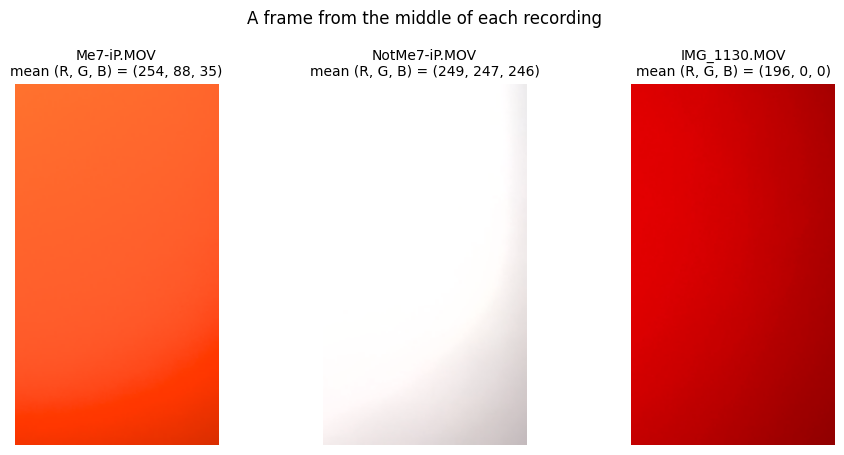

In [3]:
videos = [v for v in (v1, v2, v3) if v is not None]
fig, axes = plt.subplots(1, len(videos), figsize=(3.2 * len(videos), 4.6))
for ax, v in zip(np.atleast_1d(axes), videos):
    ax.imshow(v["thumb"])
    r, g, b = v["rgb_raw"].mean(axis=0)
    ax.set_title(f"{v['file']}\nmean (R, G, B) = ({r:.0f}, {g:.0f}, {b:.0f})", fontsize=10)
    ax.axis("off")
fig.suptitle("A frame from the middle of each recording")
plt.tight_layout()
plt.show()

**What the frames show.**

- **Video 1** is orange-red. Tissue and blood absorb blue and green light strongly and pass red, so this is what light through a fingertip looks like. The red channel is so bright that most of its pixels are clipped at 255.
- **Video 2** is nearly white, with R ≈ G ≈ B. Light that passed through a fingertip would be strongly red, so this recording does not appear to be of perfused tissue. I treat it as a control and let the analysis decide whether a pulse is present.

## Analysis functions

The functions below implement Parts 1 to 11, so each video section is just a series of function calls.

- `plot_rgb`: Part 1
- `design_bandpass`, `plot_impulse`, `plot_magnitude`, `plot_phase`: Parts 2, 3, 5, 6
- `filter_video`, `edge_analysis`, `plot_filtered`: Parts 4 and 7
- `compute_psd`, `plot_psd`: Parts 8 and 9
- `estimate_pulse`: Parts 10 and 11

In [4]:
@needs_input
def plot_rgb(v):
    t, rgb, sat = v["t_raw"], v["rgb_raw"], v["sat"]
    fig, axes = plt.subplots(4, 1, figsize=(12, 10.5), sharex=True)
    for c, ax in enumerate(axes[:3]):
        ax.plot(t, rgb[:, c], color=CH_COLORS[c], lw=0.8)
        ax.set_ylabel("Mean intensity\n(0 to 255)")
        ax.set_title(f"{CH_NAMES[c]} channel: mean = {rgb[:, c].mean():.1f}, "
                     f"{100 * sat[:, c].mean():.0f}% of pixels clipped at 255", fontsize=10)
        ax.grid(True, alpha=0.3)
    rel = 100 * (rgb / rgb.mean(axis=0) - 1)
    for c in range(3):
        axes[3].plot(t, rel[:, c], color=CH_COLORS[c], lw=0.8, label=CH_NAMES[c])
    axes[3].set_ylabel("Change from\nchannel mean (%)")
    axes[3].set_title("All three channels on a common relative scale", fontsize=10)
    axes[3].set_xlabel("Time (s)")
    axes[3].legend(loc="upper right", ncol=3)
    axes[3].grid(True, alpha=0.3)
    fig.suptitle(f"{v['label']}: average channel intensity versus time")
    plt.tight_layout()
    plt.show()

In [5]:
# Specifications, in Hz so the same design carries over to any frame rate
F_STOP_LO, F_PASS_LO = 0.40, 0.70     # Hz
F_PASS_HI, F_STOP_HI = 3.50, 3.80     # Hz
A_STOP = 40                           # dB, required stopband attenuation
A_DESIGN = 42                         # dB passed to kaiserord (its length formula is slightly optimistic for a bandpass)


@needs_input
def design_bandpass(v, verbose=True):
    fs = v["fs"]
    width = F_PASS_LO - F_STOP_LO                          # transition width (Hz)
    N, beta = kaiserord(A_DESIGN, width / (fs / 2))
    N += (N % 2 == 0)                                     # odd length: integer center tap, so it can be centered
    M = (N - 1) // 2
    fc = ((F_STOP_LO + F_PASS_LO) / 2, (F_PASS_HI + F_STOP_HI) / 2)   # -6 dB points of a windowed sinc
    h = firwin(N, fc, window=("kaiser", beta), pass_zero=False, fs=fs)

    f, H = freqz(h, worN=2**15, fs=fs)                    # causal response, f in Hz
    A = np.real(H * np.exp(1j * 2 * np.pi * f / fs * M))  # real amplitude of the centered (zero-phase) filter
    filt = dict(h=h, N=N, M=M, beta=beta, fc=fc, fs=fs, f=f, H=H, A=A)

    if verbose:
        mag = 20 * np.log10(np.maximum(np.abs(A), 1e-12))
        pb = (f >= F_PASS_LO) & (f <= F_PASS_HI)
        sb = (f <= F_STOP_LO) | (f >= F_STOP_HI)
        f3 = f[mag >= -3]
        print(f"Kaiser-window FIR bandpass for fs = {fs:g} Hz")
        print(f"  length N = {N} taps ({N / fs:.2f} s), half-length M = {M} samples ({M / fs:.2f} s), beta = {beta:.3f}")
        print(f"  cutoffs (-6 dB): {fc[0]:.2f} Hz ({60 * fc[0]:.0f} bpm) and {fc[1]:.2f} Hz ({60 * fc[1]:.0f} bpm)")
        print(f"  -3 dB band: {f3.min():.3f} to {f3.max():.3f} Hz ({60 * f3.min():.0f} to {60 * f3.max():.0f} bpm)")
        print(f"  passband {F_PASS_LO}-{F_PASS_HI} Hz: gain {mag[pb].min():+.3f} to {mag[pb].max():+.3f} dB")
        print(f"  stopbands below {F_STOP_LO} Hz and above {F_STOP_HI} Hz: at least {-mag[sb].max():.1f} dB attenuation "
              f"(spec {A_STOP} dB)")
    return filt


@needs_input
def plot_impulse(filt):
    h, M, fs = filt["h"], filt["M"], filt["fs"]
    t = (np.arange(len(h)) - M) / fs
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.stem(t, h, basefmt="k-", markerfmt=".", linefmt="C0-")
    ax.set_xlabel("Time relative to the center tap (s)    [sample index $n - M$ divided by $f_s$]")
    ax.set_ylabel("$h[n]$")
    ax.set_title(f"Impulse response: N = {filt['N']} taps ({filt['N'] / fs:.2f} s), centered at n = 0 "
                 f"(the causal version is this shifted right by M = {M} samples = {M / fs:.2f} s)")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


@needs_input
def plot_magnitude(filt):
    f, A, fs = filt["f"], filt["A"], filt["fs"]
    mag = 20 * np.log10(np.maximum(np.abs(A), 1e-12))
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

    ax = axes[0]
    ax.plot(f, mag, "C0")
    ax.fill_between([F_PASS_LO, F_PASS_HI], -120, 10, color="C2", alpha=0.12, label="Passband")
    ax.plot([0, F_STOP_LO], [-A_STOP] * 2, "r--", lw=1.2, label=f"Stopband limit (-{A_STOP} dB)")
    ax.plot([F_STOP_HI, fs / 2], [-A_STOP] * 2, "r--", lw=1.2)
    ax.set_xlim(0, fs / 2)
    ax.set_ylim(-100, 5)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("$|H(e^{j\\omega})|$ (dB)")
    ax.set_title("Magnitude response, 0 to $f_s/2$")
    ax.legend(loc="upper right")
    ax.grid(True, alpha=0.3)

    ax = axes[1]
    ax.plot(f, np.abs(A), "C0")
    ax.axvspan(F_PASS_LO, F_PASS_HI, color="C2", alpha=0.12, label="Passband (42 to 210 bpm)")
    for fc in filt["fc"]:
        ax.axvline(fc, color="k", ls=":", lw=1)
    ax.axhline(1 / np.sqrt(2), color="gray", ls="--", lw=0.8, label="$1/\\sqrt{2}$ (-3 dB)")
    ax.set_xlim(0, 5)
    ax.set_ylim(0, 1.1)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("$|H(e^{j\\omega})|$ (linear)")
    ax.set_title("Zoom on the band of interest (dotted: -6 dB cutoffs)")
    sec = ax.secondary_xaxis("top", functions=(lambda x: 60 * x, lambda x: x / 60))
    sec.set_xlabel("Beats per minute")
    ax.legend(loc="lower center")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


@needs_input
def plot_phase(filt):
    f, A, M, fs = filt["f"], filt["A"], filt["M"], filt["fs"]
    shown = np.abs(A) >= 10 ** (-A_STOP / 20)        # phase only where |H| > -40 dB; elsewhere the output is ~0
    phase_zero = np.where(A < 0, np.pi, 0.0)         # angle of a real-valued response
    phase_causal = phase_zero - 2 * np.pi * f / fs * M
    phase_zero[~shown] = np.nan
    phase_causal[~shown] = np.nan

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    ax = axes[0]
    ax.plot(f, phase_zero, "C0", lw=2)
    ax.axvspan(F_PASS_LO, F_PASS_HI, color="C2", alpha=0.12, label="Passband")
    ax.set_yticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
    ax.set_yticklabels(["$-\\pi$", "$-\\pi/2$", "0", "$\\pi/2$", "$\\pi$"])
    ax.set_ylim(-np.pi - 0.3, np.pi + 0.3)
    ax.set_xlim(0, 6)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("Phase (rad)")
    ax.set_title("As applied (centered, non-causal): zero phase")
    ax.legend(loc="upper right")
    ax.grid(True, alpha=0.3)

    ax = axes[1]
    ax.plot(f, -2 * np.pi * f / fs * M, "k--", lw=0.8, label=f"$-\\omega M$, M = {M}")
    ax.plot(f, phase_causal, "C1", lw=2, label="Phase of $h[n-M]$")
    ax.axvspan(F_PASS_LO, F_PASS_HI, color="C2", alpha=0.12)
    ax.set_xlim(0, 6)
    ax.set_ylim(-160, 5)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("Phase (rad, unwrapped)")
    ax.set_title(f"Causal version: linear phase, group delay = M = {M} samples = {M / fs:.2f} s")
    ax.legend(loc="lower left")
    ax.grid(True, alpha=0.3)
    fig.suptitle("Phase response (shown only where $|H| > -40$ dB; the stopband output is negligible)", fontsize=10)
    plt.tight_layout()
    plt.show()

In [6]:
@needs_input
def filter_video(v, filt):
    # Zero-phase (centered) FIR filtering. The mean is removed first so that the zero padding
    # beyond the record does not create a large step at each end.
    h, M = filt["h"], filt["M"]
    x0 = v["x"] - v["x"].mean(axis=0)
    L = len(x0)
    y = np.column_stack([np.convolve(x0[:, c], h)[M:M + L] for c in range(3)])
    steady = slice(M, L - M)                                 # samples whose window lies fully inside the record
    return dict(t=v["t"], y=y, steady=steady, M=M, fs=v["fs"], x0=x0, h=h)


def reflect_filter(x0, h):
    # Same filter, but the record is extended by odd reflection instead of zeros (used only for Part 4).
    M = (len(h) - 1) // 2
    out = []
    for c in range(x0.shape[1]):
        x = x0[:, c]
        xp = np.concatenate([2 * x[0] - x[M:0:-1], x, 2 * x[-1] - x[-2:-M - 2:-1]])
        out.append(np.convolve(xp, h, mode="valid"))
    return np.column_stack(out)


def shade_edges(ax, yd):
    t, M, fs = yd["t"], yd["M"], yd["fs"]
    ax.axvspan(t[0], t[0] + M / fs, color="gray", alpha=0.18, lw=0)
    ax.axvspan(t[-1] - M / fs, t[-1], color="gray", alpha=0.18, lw=0, label="Edge region (first/last M samples)")


@needs_input
def edge_analysis(v, filt):
    yd = filter_video(v, filt)
    h, M, fs = filt["h"], filt["M"], filt["fs"]
    t, y = yd["t"], yd["y"]

    # (a) Worst-case bound: fraction of the filter's total |h| that falls off the end of the record
    #     when the output sample is j samples from the edge.
    missing = np.array([np.abs(h[M + j + 1:]).sum() for j in range(M + 1)]) / np.abs(h).sum()
    j1 = np.argmax(missing < 0.01)

    # (b) Measured: how much the output changes if the record is extended differently (zeros vs
    #     odd reflection). Away from the edges both give exactly the same output.
    diff = np.abs(y - reflect_filter(yd["x0"], h))
    rms = y[yd["steady"]].std(axis=0)
    rel_db = 20 * np.log10(np.maximum(diff / rms, 1e-5))

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    ax = axes[0]
    ax.semilogy(np.arange(M + 1) / fs, np.maximum(missing, 1e-7), "C0")
    ax.axhline(0.01, color="gray", ls="--", lw=0.8)
    ax.axvline(j1 / fs, color="C1", ls="--", lw=1, label=f"Below 1% after {j1 / fs:.2f} s")
    ax.axvline(M / fs, color="k", ls="--", lw=1, label=f"Complete window after M/fs = {M / fs:.2f} s")
    ax.set_xlabel("Distance of the output sample from the edge of the record (s)")
    ax.set_ylabel("Missing $\\sum|h|$ / total $\\sum|h|$")
    ax.set_title("Worst-case bound on the edge error")
    ax.legend()
    ax.grid(True, which="both", alpha=0.3)

    ax = axes[1]
    for c in range(3):
        ax.plot(t, rel_db[:, c], color=CH_COLORS[c], lw=0.9, label=CH_NAMES[c])
    shade_edges(ax, yd)
    ax.axhline(-40, color="gray", ls="--", lw=0.8)
    ax.set_ylim(-100, 20)
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("|zero-pad - reflect| / RMS (dB)")
    ax.set_title(f"{v['label']}: measured edge sensitivity")
    ax.legend(loc="lower center", ncol=2, fontsize=8)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    print(f"Complete filter window (strict):       {M} samples = {M / fs:.2f} s from each end")
    print(f"Worst-case bound below 1% of max |y|:  {j1} samples = {j1 / fs:.2f} s from each end")
    for c in range(3):
        loud = np.flatnonzero(rel_db[:, c] >= -40)           # difference at or above 1% of the steady-state RMS
        half = len(t) // 2
        start = (loud[loud < half].max() + 1) if (loud < half).any() else 0
        end = (loud[loud >= half].min() - 1) if (loud >= half).any() else len(t) - 1
        print(f"{CH_NAMES[c]:5s}: measured difference stays below 1% of RMS from {t[start]:.2f} s to "
              f"{t[end]:.2f} s  (i.e. {t[start]:.2f} s and {t[-1] - t[end]:.2f} s in from the ends)")


@needs_input
def plot_filtered(yd, label):
    t, y, fs = yd["t"], yd["y"], yd["fs"]
    fig, axes = plt.subplots(4, 1, figsize=(12, 11))
    for c, ax in enumerate(axes[:3]):
        ax.plot(t, y[:, c], color=CH_COLORS[c], lw=0.8)
        shade_edges(ax, yd)
        ax.set_xlim(t[0], t[-1])
        ax.set_ylabel("Filtered\nintensity")
        ax.set_title(f"{CH_NAMES[c]} channel after the bandpass filter "
                     f"(steady-state RMS = {y[yd['steady'], c].std():.3f})", fontsize=10)
        ax.grid(True, alpha=0.3)
    axes[0].legend(loc="upper right")
    axes[2].set_xlabel("Time (s)")

    # Zoom: 8 s from the middle, each channel scaled by its own RMS so the shapes can be compared
    ax = axes[3]
    mid = t[len(t) // 2]
    sel = (t >= mid - 4) & (t <= mid + 4)
    for c in range(3):
        ax.plot(t[sel], y[sel, c] / y[yd["steady"], c].std(), color=CH_COLORS[c], lw=1.2, label=CH_NAMES[c])
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Filtered / RMS")
    ax.set_title("8-second zoom from the middle of the record, each channel normalized by its RMS", fontsize=10)
    ax.legend(loc="upper right", ncol=3)
    ax.grid(True, alpha=0.3)
    fig.suptitle(f"{label}: filter output")
    plt.tight_layout()
    plt.show()

In [7]:
SEG_SEC = 10.0        # Welch segment length (s)
NFFT = 8192           # zero-padded FFT length: PSD sampled every fs/NFFT Hz


@needs_input
def compute_psd(yd):
    fs = yd["fs"]
    ys = yd["y"][yd["steady"]]                       # steady-state part only (edges removed, Part 4)
    nper = int(round(SEG_SEC * fs))
    f, P_welch = welch(ys, fs, window="hann", nperseg=nper, noverlap=nper // 2, nfft=NFFT,
                       detrend=False, scaling="density", axis=0)
    _, P_per = periodogram(ys, fs, window="hann", nfft=NFFT, detrend=False, scaling="density", axis=0)
    n_seg = 1 + (len(ys) - nper) // (nper // 2)
    return dict(f=f, welch=P_welch, per=P_per, n_seg=n_seg, nper=nper, T=len(ys) / fs, fs=fs)


@needs_input
def plot_psd(psd, label):
    f, Pw, Pp = psd["f"], psd["welch"], psd["per"]
    bpm = 60 * f
    fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
    for c, ax in enumerate(axes):
        ax.plot(bpm, 10 * np.log10(Pp[:, c] + 1e-20), color="gray", lw=0.6, alpha=0.6,
                label=f"Hann periodogram, whole {psd['T']:.1f} s steady-state record")
        ax.plot(bpm, 10 * np.log10(Pw[:, c] + 1e-20), color=CH_COLORS[c], lw=1.8,
                label=f"Welch: Hann, {SEG_SEC:g} s segments, 50% overlap ({psd['n_seg']} segments)")
        ax.axvspan(60 * F_PASS_LO, 60 * F_PASS_HI, color="C2", alpha=0.08, label="Filter passband")
        peak = 10 * np.log10(Pw[:, c].max())
        ax.set_ylim(peak - 60, peak + 10)
        ax.set_ylabel("PSD (dB re 1 intensity$^2$/Hz)")
        ax.set_title(f"{CH_NAMES[c]} channel", fontsize=10)
        ax.grid(True, alpha=0.3)
    axes[0].legend(loc="upper right", fontsize=8)
    axes[-1].set_xlim(0, 360)
    axes[-1].set_xlabel("Frequency (beats per minute; 60 bpm = 1 Hz)")
    fig.suptitle(f"{label}: power spectral density of the filtered channels")
    plt.tight_layout()
    plt.show()

In [8]:
PEAK_HALF_WIDTH = 2 / SEG_SEC   # Hz: half-width of the Hann main lobe for a SEG_SEC segment
FRAC_MIN = 0.5                  # minimum fraction of in-band power in the peak
IQR_MAX = 10.0                  # bpm: maximum spread of the 10-second estimates
WIN_SEC, HOP_SEC = 10.0, 1.0    # sliding-window check


def peak_frequency(f, P):
    # Largest in-band peak, with a check that it is not the 2nd harmonic of a lower peak.
    band = (f >= F_PASS_LO) & (f <= F_PASS_HI)
    idx = np.flatnonzero(band)
    i = idx[np.argmax(P[idx])]
    f0 = f[i]
    half = band & (np.abs(f - f0 / 2) <= PEAK_HALF_WIDTH / 2)
    if half.any() and P[half].max() >= 0.5 * P[i]:
        f0 = f[np.flatnonzero(half)[np.argmax(P[half])]]
    frac = P[band & (np.abs(f - f0) <= PEAK_HALF_WIDTH)].sum() / P[band].sum()
    return f0, frac


@needs_input
def estimate_pulse(yd, psd, v, reference_bpm=None):
    fs = yd["fs"]
    ys = yd["y"][yd["steady"]]
    win, hop = int(round(WIN_SEC * fs)), int(round(HOP_SEC * fs))
    starts = np.arange(0, len(ys) - win + 1, hop)
    t_win = (yd["steady"].start + starts + win / 2) / fs

    rows = []
    track = np.zeros((len(starts), 3))
    for c in range(3):
        f0, frac = peak_frequency(psd["f"], psd["welch"][:, c])
        for k, s in enumerate(starts):
            fw, Pw = periodogram(ys[s:s + win, c], fs, window="hann", nfft=NFFT, detrend=False)
            track[k, c] = 60 * peak_frequency(fw, Pw)[0]
        q75, q25 = np.percentile(track[:, c], [75, 25])
        rows.append(dict(ch=CH_NAMES[c], mean=v["x"][:, c].mean(), clip=100 * v["sat"][:, c].mean(),
                         rms=ys[:, c].std(), acdc=100 * ys[:, c].std() / v["x"][:, c].mean(),
                         bpm=60 * f0, frac=frac, med=np.median(track[:, c]), iqr=q75 - q25,
                         present=(frac >= FRAC_MIN) and (q75 - q25 <= IQR_MAX)))

    print(f"{'Channel':7s} {'Mean':>6s} {'Clipped':>8s} {'Pulse RMS':>10s} {'AC/DC':>7s} {'Welch HR':>9s} "
          f"{'Peak frac':>10s} {'10-s median':>12s} {'10-s IQR':>9s}  Pulse?")
    for r in rows:
        print(f"{r['ch']:7s} {r['mean']:6.1f} {r['clip']:7.1f}% {r['rms']:10.3f} {r['acdc']:6.3f}% "
              f"{r['bpm']:5.1f} bpm {r['frac']:10.2f} {r['med']:8.1f} bpm {r['iqr']:5.1f} bpm  "
              f"{'yes' if r['present'] else 'no'}")

    present = [r for r in rows if r["present"]]
    print()
    if len(present) >= 2:
        best = max(present, key=lambda r: r["frac"])
        spread = max(r["bpm"] for r in present) - min(r["bpm"] for r in present)
        print(f"Pulse PRESENT in {len(present)} of 3 channels. Estimate: {best['bpm']:.1f} bpm "
              f"(from the {best['ch']} channel; the passing channels agree within {spread:.1f} bpm).")
    else:
        best = None
        print(f"Pulse NOT present: only {len(present)} of 3 channels pass both tests "
              f"(peak fraction >= {FRAC_MIN}, 10-s IQR <= {IQR_MAX:g} bpm).")
    if reference_bpm is not None and best is not None:
        print(f"Reference measured during the recording: {reference_bpm} bpm "
              f"(error {best['bpm'] - reference_bpm:+.1f} bpm)")

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    ax = axes[0]
    for c in range(3):
        ax.plot(t_win, track[:, c], "o-", ms=4, color=CH_COLORS[c], label=CH_NAMES[c])
    ax.set_ylim(40, 220)
    ax.set_xlabel("Center of 10-second window (s)")
    ax.set_ylabel("Peak frequency (bpm)")
    ax.set_title("Stability check: estimate from each 10-s window (1-s hop)")
    ax.legend()
    ax.grid(True, alpha=0.3)

    ax = axes[1]
    sel = (psd["f"] >= 0.5) & (psd["f"] <= 4.0)
    for c in range(3):
        P = psd["welch"][sel, c]
        ax.plot(60 * psd["f"][sel], P / P.max(), color=CH_COLORS[c], lw=1.5,
                label=f"{CH_NAMES[c]}: {rows[c]['bpm']:.1f} bpm, frac {rows[c]['frac']:.2f}")
    if best is not None:
        for k in (1, 2, 3):
            if k * best["bpm"] <= 240:
                ax.axvline(k * best["bpm"], color="k", ls="--" if k == 1 else ":", lw=1)
    ax.set_xlabel("Frequency (bpm)")
    ax.set_ylabel("Welch PSD / peak")
    ax.set_title("Welch PSDs normalized to their peak" + (" (dashed: estimate, dotted: harmonics)" if best else ""))
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    fig.suptitle(v["label"])
    plt.tight_layout()
    plt.show()
    return dict(rows=rows, best=best, track=track, t_win=t_win)

# Video 1: `Me7-iP.MOV`

## Part 1: Plot the average intensity of the red, blue, and green channels versus time

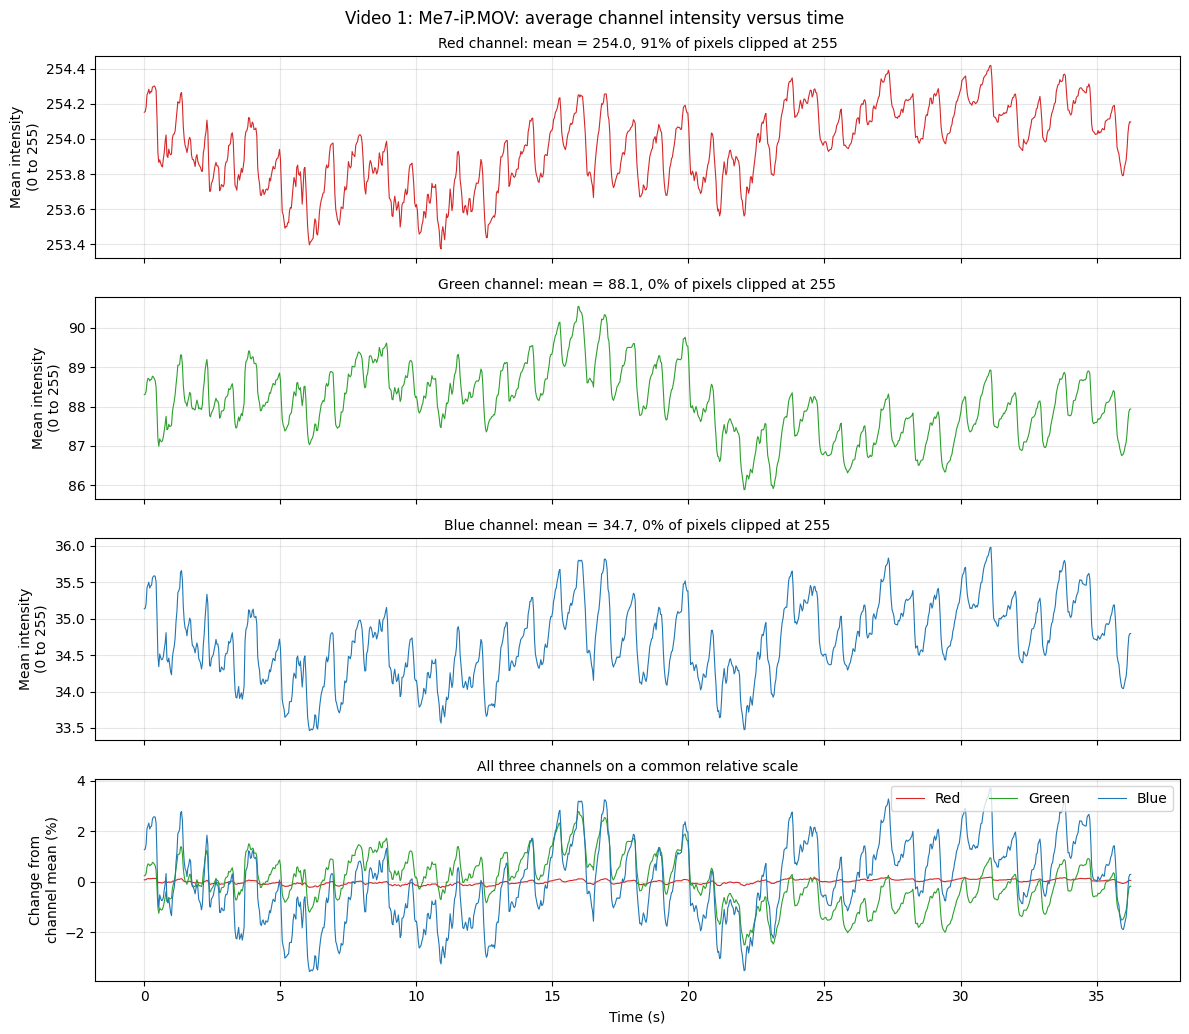

In [9]:
plot_rgb(v1)

**Observations.**

- **Green and blue** show a clear oscillation of about one cycle per second, riding on a slow drift.
- **Red** barely moves. About 91% of its pixels are clipped at 255, so only the remaining 9% can change.
- **Relative size.** The bottom plot puts all three channels on the same percent scale. The beat-to-beat change is about 1% of the green and blue means, and much smaller for red.

## Part 2: Design a filter to isolate the pulsatile frequency of interest

### What the filter has to separate

| Component | Frequency | Keep? |
|---|---|---|
| Mean light level (DC) | 0 Hz | No |
| Drift: auto-exposure, finger pressure and position | below about 0.3 Hz | No |
| Respiration (6 to 24 breaths per minute) | 0.1 to 0.4 Hz | No |
| **Pulse fundamental** (42 to 210 bpm) | **0.7 to 3.5 Hz** | **Yes** |
| Sensor noise and fast motion | above about 4 Hz | No |

### Design decisions

**Filter type: linear-phase FIR bandpass, Kaiser window, applied non-causally (centered).**

- **Bandpass.** Both the low-frequency drift and the high-frequency noise have to go, so neither a lowpass nor a highpass alone is enough.
- **FIR with linear phase, applied centered.** A symmetric FIR filter applied centered at $n = 0$ has zero phase. It does not shift the pulse in time or distort its shape. FIR filters are also always stable, and the edge effects last exactly $M$ samples, which makes Part 4 straightforward.
- **Kaiser window.** One parameter, $\beta$, sets the stopband attenuation, and `kaiserord` gives the required length directly from the attenuation and the transition width. The Kaiser window is close to optimal in its tradeoff between main-lobe width and sidelobe level.
- **Why not IIR (Butterworth).** An IIR filter would be shorter, but its phase is nonlinear. Making it zero-phase requires forward-backward filtering, which squares the magnitude response and makes the edge transient decay only asymptotically. Computation is not a concern offline (239 taps × about 1100 samples), so I chose the FIR filter.

**Specifications.**

| Specification | Value | Rationale |
|---|---|---|
| Lower stopband edge | 0.40 Hz (24 /min) | Rejects respiration up to 24 breaths per minute, plus slower drift |
| Lower passband edge | 0.70 Hz (42 bpm) | Below the lowest plausible resting heart rate |
| Upper passband edge | 3.50 Hz (210 bpm) | Above any plausible heart rate for a seated subject. It also keeps the 2nd harmonic for rates up to 105 bpm, which preserves the pulse shape |
| Upper stopband edge | 3.80 Hz | The Kaiser window method uses one transition width for both edges (0.3 Hz) |
| Stopband attenuation | ≥ 40 dB | The drift in the raw signals is up to about 10× (20 dB) larger than the pulse. 40 dB leaves it about 20 dB below the pulse |
| Cutoff frequencies | **0.55 Hz and 3.65 Hz** (−6 dB) | The middle of each transition band. For a windowed-sinc design, this is where the gain is 0.5 |
| Length | $N = 239$ taps (7.97 s), $M = 119$ | From `kaiserord` for a 0.3 Hz transition. Its length formula is slightly optimistic for a bandpass: asking for 40 dB gives only 39.2 dB, so I ask for 42 dB, which gives 40.0 dB |

**The key tradeoff is the transition width.** The length grows as $1/\Delta f$. A 0.3 Hz transition is what separates fast breathing (0.4 Hz) from a slow heart rate (0.7 Hz). Narrower transitions would lengthen the filter and the edge effects (Part 4). With a 36 s record, I lose about 4 s at each end.

**Edge handling.** Each channel's mean is subtracted before filtering, so the zero padding beyond the ends of the record does not create a large step. The samples within $M$ of either end are flagged as the edge region and excluded from the PSD.

In [10]:
filt1 = design_bandpass(v1)

Kaiser-window FIR bandpass for fs = 30 Hz
  length N = 239 taps (7.97 s), half-length M = 119 samples (3.97 s), beta = 3.631
  cutoffs (-6 dB): 0.55 Hz (33 bpm) and 3.65 Hz (219 bpm)
  -3 dB band: 0.594 to 3.607 Hz (36 to 216 bpm)
  passband 0.7-3.5 Hz: gain -0.042 to +0.099 dB
  stopbands below 0.4 Hz and above 3.8 Hz: at least 40.0 dB attenuation (spec 40 dB)


## Part 3: Plot the impulse response of your filter

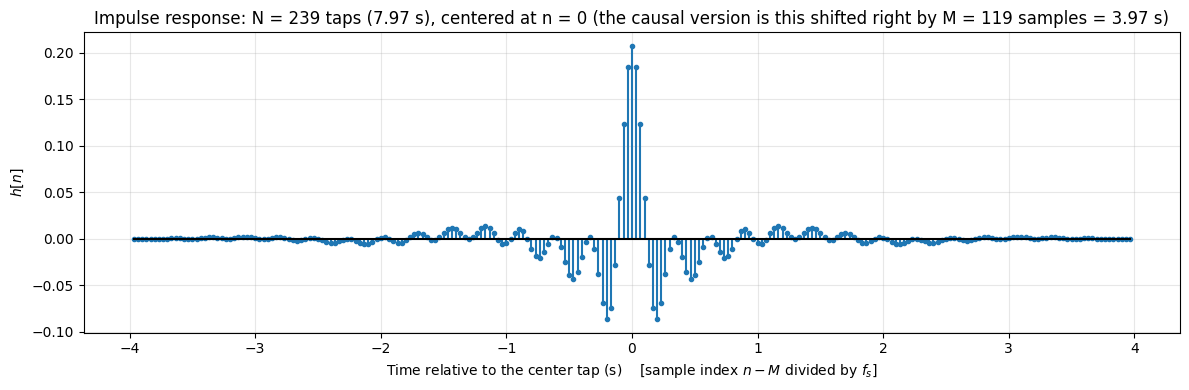

In [11]:
plot_impulse(filt1)

## Part 4: How long do you estimate it would take for the edge effects to become negligible for your filter?

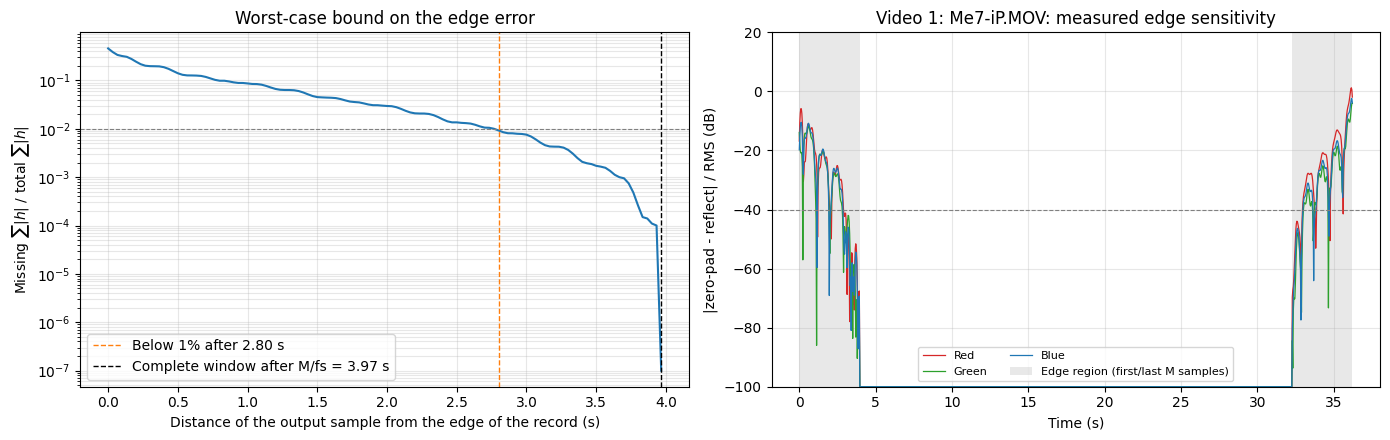

Complete filter window (strict):       119 samples = 3.97 s from each end
Worst-case bound below 1% of max |y|:  84 samples = 2.80 s from each end
Red  : measured difference stays below 1% of RMS from 2.90 s to 32.97 s  (i.e. 2.90 s and 3.27 s in from the ends)
Green: measured difference stays below 1% of RMS from 2.83 s to 33.00 s  (i.e. 2.83 s and 3.23 s in from the ends)
Blue : measured difference stays below 1% of RMS from 2.87 s to 32.97 s  (i.e. 2.87 s and 3.27 s in from the ends)


In [12]:
edge_analysis(v1, filt1)

**Answer: the edge effects are small after about 3 s and gone after 3.97 s from each end. I treat the first and last 3.97 s ($M/f_s = 119/30$) as the edge region.**

The filter is applied centered, so the output $y[n]$ uses the inputs $x[n-M]$ through $x[n+M]$. The window is complete only for $M \le n \le L-1-M$. Within 3.97 s of either end, some of the needed samples do not exist, so the output depends on what is assumed beyond the record.

Two checks:

- **Worst-case bound (left).** The fraction of $\sum|h|$ that falls off the end of the record drops below 1% at 2.80 s. The taps near $|n| = M$ are small, so the edge error is already small before the window is complete.
- **Measured on this video (right).** I filtered the record twice: once with zero padding and once with odd reflection beyond the ends. Wherever the window is complete, the two outputs are identical. For this video, the difference stays below 1% of the steady-state RMS (−40 dB) from about 2.9 s after the start to 3.3 s before the end. This difference only shows how sensitive the output is to the assumed extension, so it is a sanity check rather than the true error.

The edge error depends on how large the signal is near the ends. In Video 2, which starts with a large auto-exposure transient, the measured difference takes 3.5 to 3.8 s to settle, nearly the full $M/f_s$. So I use the strict value. I discard 3.97 s at each end, which leaves 28.3 s of steady-state output for the PSD.

## Part 5: Plot the magnitude response of your filter

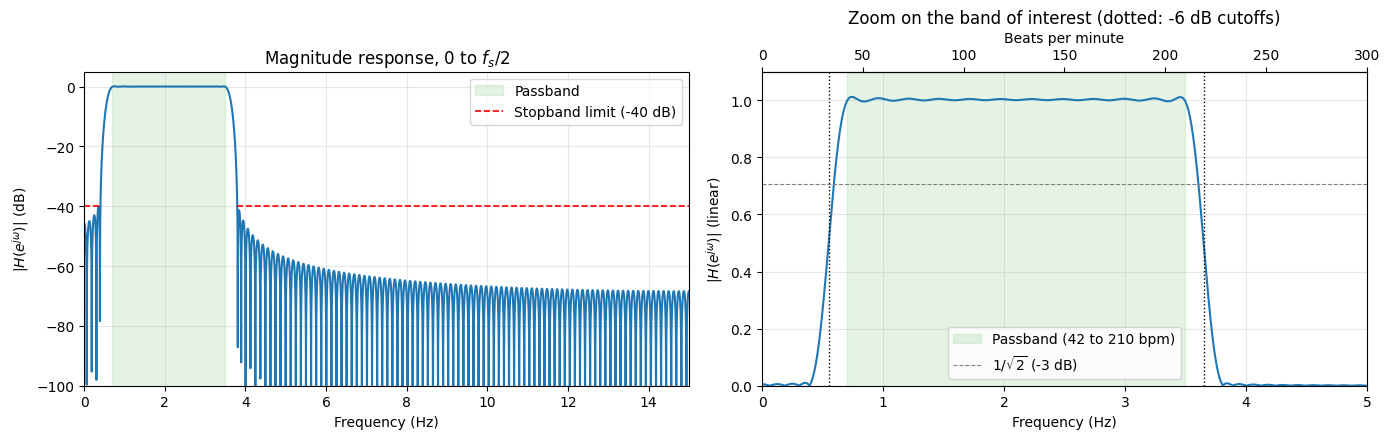

In [13]:
plot_magnitude(filt1)

- The passband (0.7 to 3.5 Hz, or 42 to 210 bpm) is flat to within 0.1 dB (−0.04 to +0.10 dB).
- Both stopbands are attenuated by at least 40.0 dB. The upper sidelobes keep falling, to about −70 dB near $f_s/2$.
- The −6 dB cutoffs are at 0.55 Hz and 3.65 Hz.

## Part 6: Plot the phase response of your filter

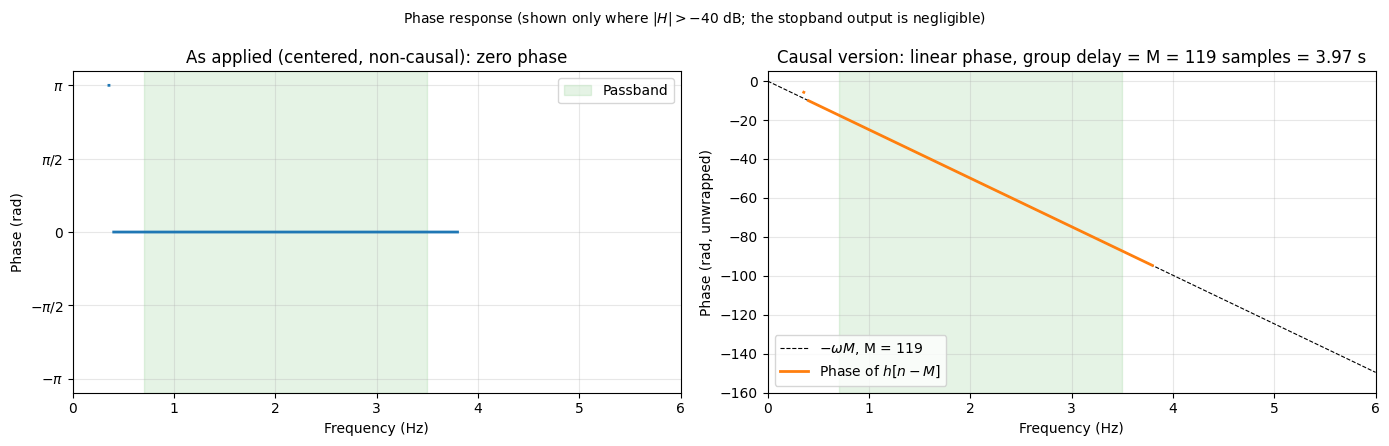

In [14]:
plot_phase(filt1)

- **As applied (left).** The filter is centered at $n = 0$ and even-symmetric, so $H(e^{j\omega}) = A(\omega)$ is real. The phase is 0 across the entire passband: the output is not shifted in time. Inside the stopbands, $A(\omega)$ changes sign from one sidelobe to the next, so the phase there alternates between 0 and $\pi$. Those sidelobes are at least 40 dB down, so the phase is plotted only where $|H| > -40$ dB.
- **Causal version (right).** Implementing the same taps as $h[n - M]$ adds the linear phase $-\omega M$. That is a constant group delay of $M = 119$ samples (3.97 s). It would delay every frequency by the same amount, so the pulse shape would still not be distorted, but the output would lag the input by about 4 s. Applying the filter centered removes this delay.

## Part 7: Plot the output of your filter for each of the color channels

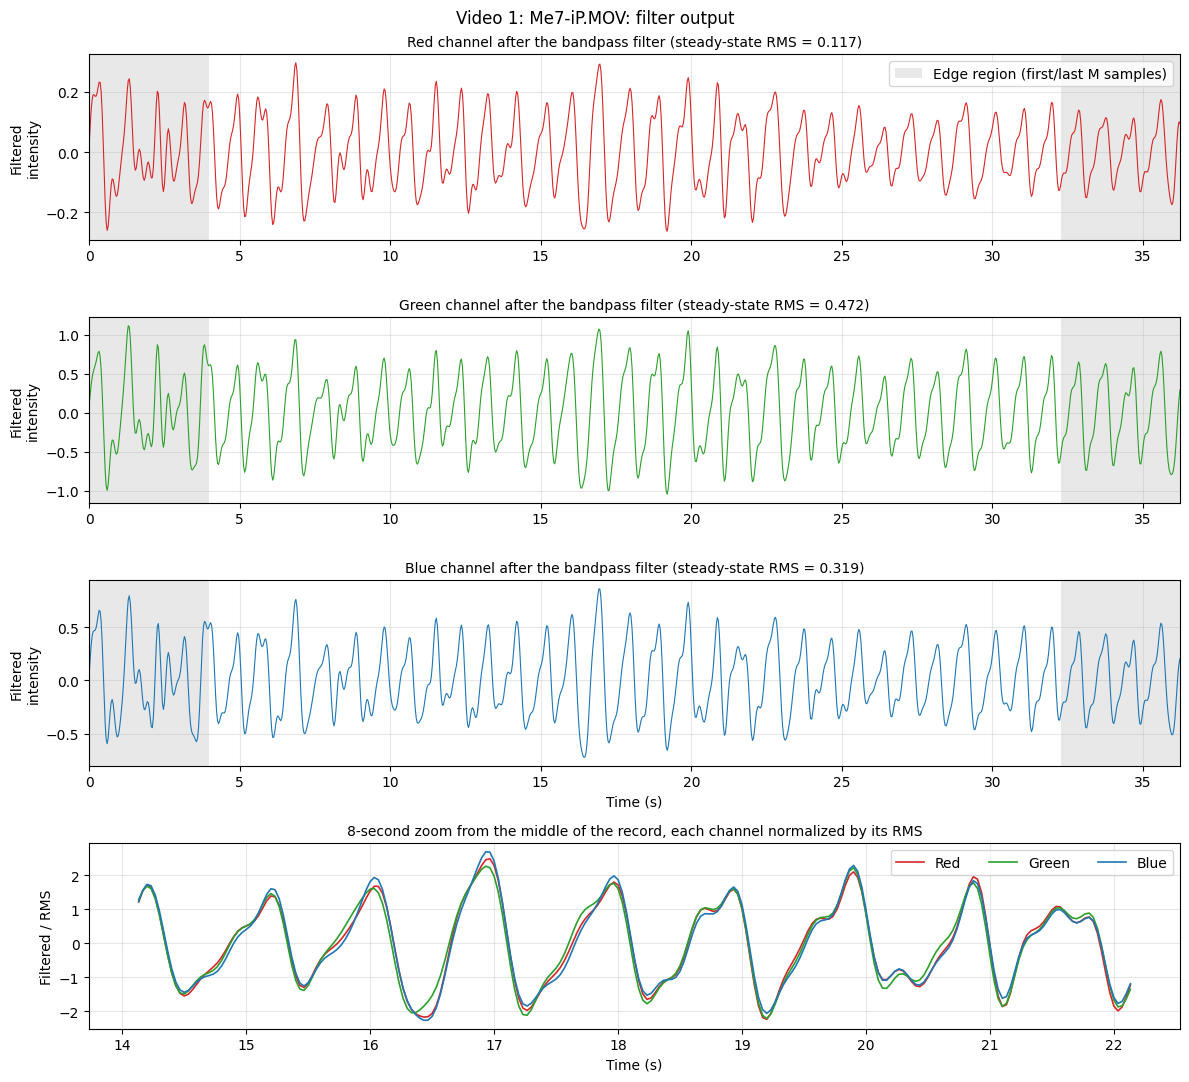

In [15]:
y1 = filter_video(v1, filt1) if v1 is not None else None
plot_filtered(y1, v1['label'] if v1 is not None else '')

- After filtering, all three channels show a clean, regular pulse of about one beat per second with a stable amplitude.
- The 8-second zoom shows the PPG waveform: a fast rise and a slower decay each beat.
- The red channel's pulse is much smaller in absolute terms because of clipping, but its shape matches the green and blue channels.
- The gray regions are the edge regions from Part 4. They are excluded from everything that follows.

## Part 8: Determine an approach to estimating the power spectral density

### PSD design decisions

| Decision | Choice | Rationale |
|---|---|---|
| Data | The filtered output, steady-state samples only (28.3 s) | Edge transients (Part 4) would leak into the spectrum. The DC and drift are already removed |
| Method | **Welch's method** (averaged, windowed periodograms) | A single periodogram has a standard deviation equal to its mean at every frequency, no matter how long the record is. Averaging segments reduces this variance |
| Window | Hann | Sidelobes at −31 dB that fall off at 18 dB per octave, so the strong fundamental does not leak into and hide its harmonics |
| Segment length | 10 s (300 samples) | Holds at least 7 beats even at 42 bpm. The Hann main lobe is $4/T = 0.4$ Hz wide (−3 dB width about 0.14 Hz, or 8.6 bpm). The heart rate itself varies by several bpm within each breath (respiratory sinus arrhythmia), so finer resolution gains little. Shorter segments give more averaging |
| Overlap | 50% | With a Hann window, 50% overlap recovers most of the variance reduction of fully independent segments. It gives 4 segments here |
| FFT length | 8192 (zero-padded) | Samples the PSD every 0.0037 Hz (0.22 bpm), so the peak location is not quantized to the 0.1 Hz (6 bpm) spacing of a 300-point FFT. Zero padding does **not** improve the resolution |
| Scaling | One-sided density (intensity²/Hz) | The area under the PSD equals the average power of the filtered signal |

For comparison, each plot also shows (in gray) a single Hann-windowed periodogram of the entire 28.3 s steady-state record. It has better resolution but much higher variance.

## Part 9: Plot the Power Spectral Density for each of the color channels

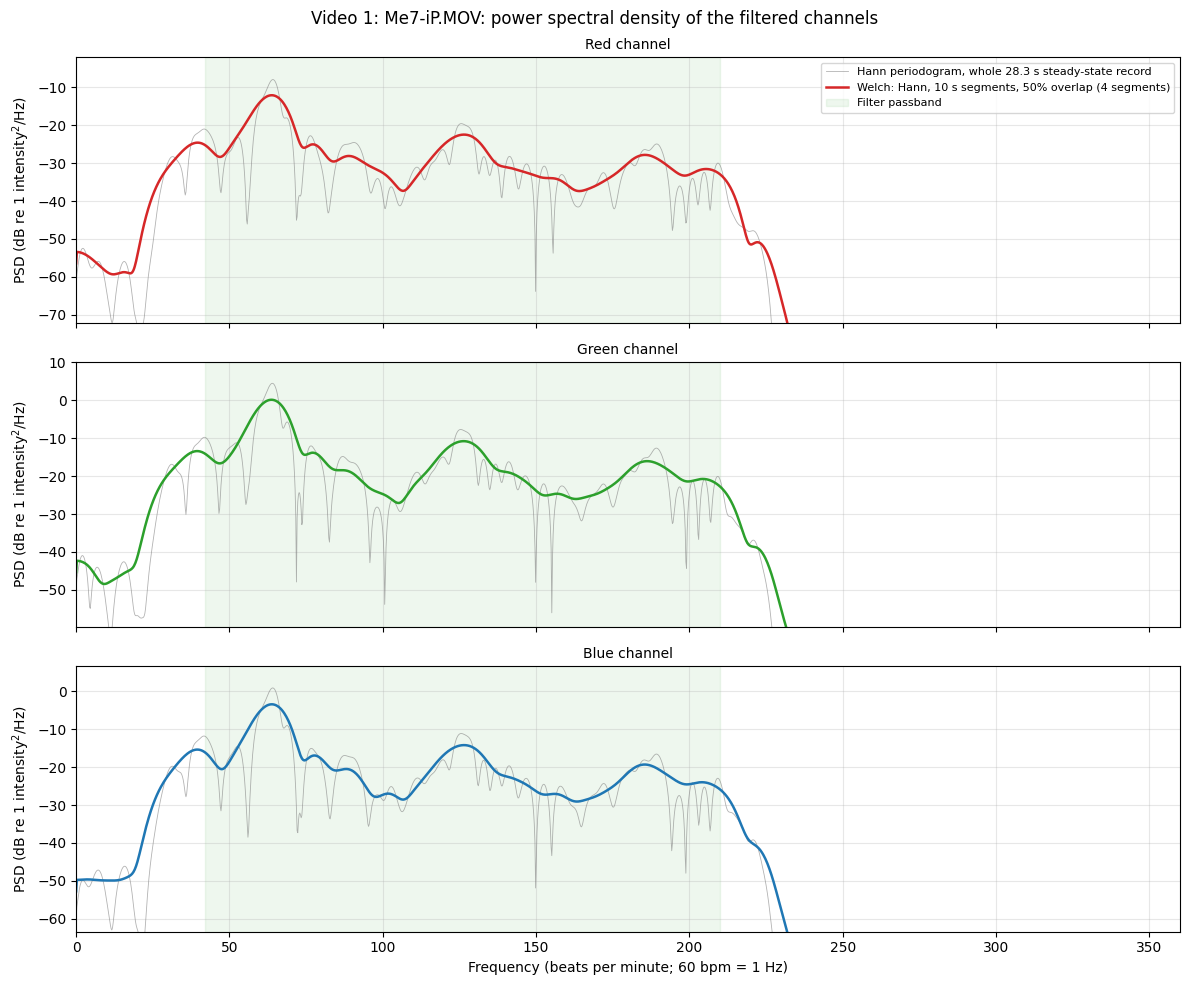

In [16]:
psd1 = compute_psd(y1)
plot_psd(psd1, v1['label'] if v1 is not None else '')

- All three channels have a dominant peak at about 64 bpm.
- Smaller peaks appear at about 128 and 192 bpm: the 2nd and 3rd harmonics, which come from the non-sinusoidal pulse shape.
- Below about 25 bpm and above about 230 bpm, the PSD drops 40 dB or more below the peak, as the filter was designed to do.
- The gray single periodogram shows the same peaks but is much noisier between them. This is the variance that Welch averaging removes.

## Part 10: Estimate the pulse (heart) rate, if present

### Estimation method

1. **Peak.** Find the largest Welch PSD peak in the passband (0.7 to 3.5 Hz).
2. **Harmonic check.** If the PSD near half that frequency (still within the passband) is at least half as large as the peak, take the lower frequency. This keeps the 2nd harmonic from being reported as the heart rate.
3. **Presence test.** Every spectrum has a largest peak, even pure noise, so before reporting a heart rate I require both of the following:
   - **Peak fraction ≥ 0.5.** The power within ±0.2 Hz of the peak (the Hann main-lobe half-width, $2/T$) must be at least half of the passband power. A flat noise spectrum would give about 0.4 / 2.8 ≈ 0.14.
   - **Stability.** The same estimator applied to 10-second windows (1-second hop) must give an interquartile range ≤ 10 bpm. A resting heart rate does not jump around, but a noise peak does.

   A pulse is declared present if at least 2 of the 3 channels pass both tests. The reported rate comes from the passing channel with the largest peak fraction.

Channel   Mean  Clipped  Pulse RMS   AC/DC  Welch HR  Peak frac  10-s median  10-s IQR  Pulse?
Red      254.0    90.8%      0.117  0.046%  63.7 bpm       0.77     64.4 bpm   3.3 bpm  yes
Green     88.1     0.0%      0.472  0.536%  63.7 bpm       0.81     64.4 bpm   3.2 bpm  yes
Blue      34.7     0.0%      0.319  0.920%  63.7 bpm       0.79     64.4 bpm   3.1 bpm  yes

Pulse PRESENT in 3 of 3 channels. Estimate: 63.7 bpm (from the Green channel; the passing channels agree within 0.0 bpm).


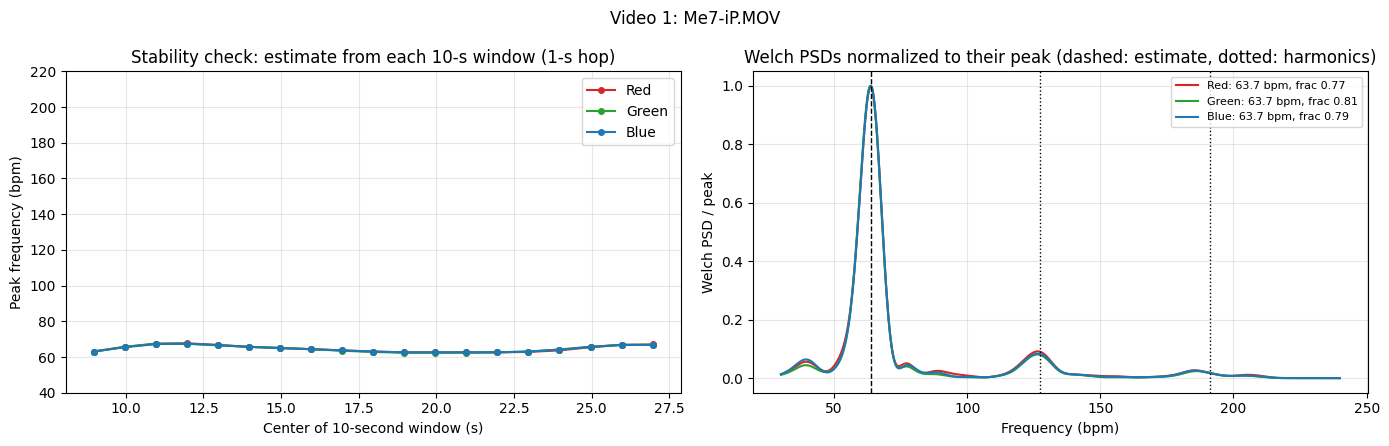

In [17]:
hr1 = estimate_pulse(y1, psd1, v1)

**Pulse present. Estimated heart rate: about 64 bpm (1.06 Hz).**

- All three channels independently give 63.7 bpm.
- The peak holds about 80% of the in-band power.
- The 10-second estimates stay within a few bpm for the whole recording.

## Part 11: Which color channels were most helpful for estimating the pulse rate?

**Green was the most helpful, with blue a close second. Red was the least helpful.**

- **Green** has the largest pulsatile amplitude in intensity units and the largest peak fraction. Hemoglobin absorbs green light strongly, so changes in blood volume produce a large change in the transmitted green light.
- **Blue** has the largest *relative* modulation (AC/DC), but its mean is low (about 35 out of 255), so its absolute pulse amplitude is smaller than green's.
- **Red** carries the most light through the finger, but about 91% of its pixels are clipped at 255. Its average therefore barely changes, and its pulse amplitude is about 10× smaller than green's. It still gives the same heart rate, because the unclipped 9% of pixels follow the pulse (its filtered output is highly correlated with green and blue). It would be the best channel if the exposure were lower.

# Video 2: `NotMe7-iP.MOV`

## Part 1: Plot the average intensity of the red, blue, and green channels versus time

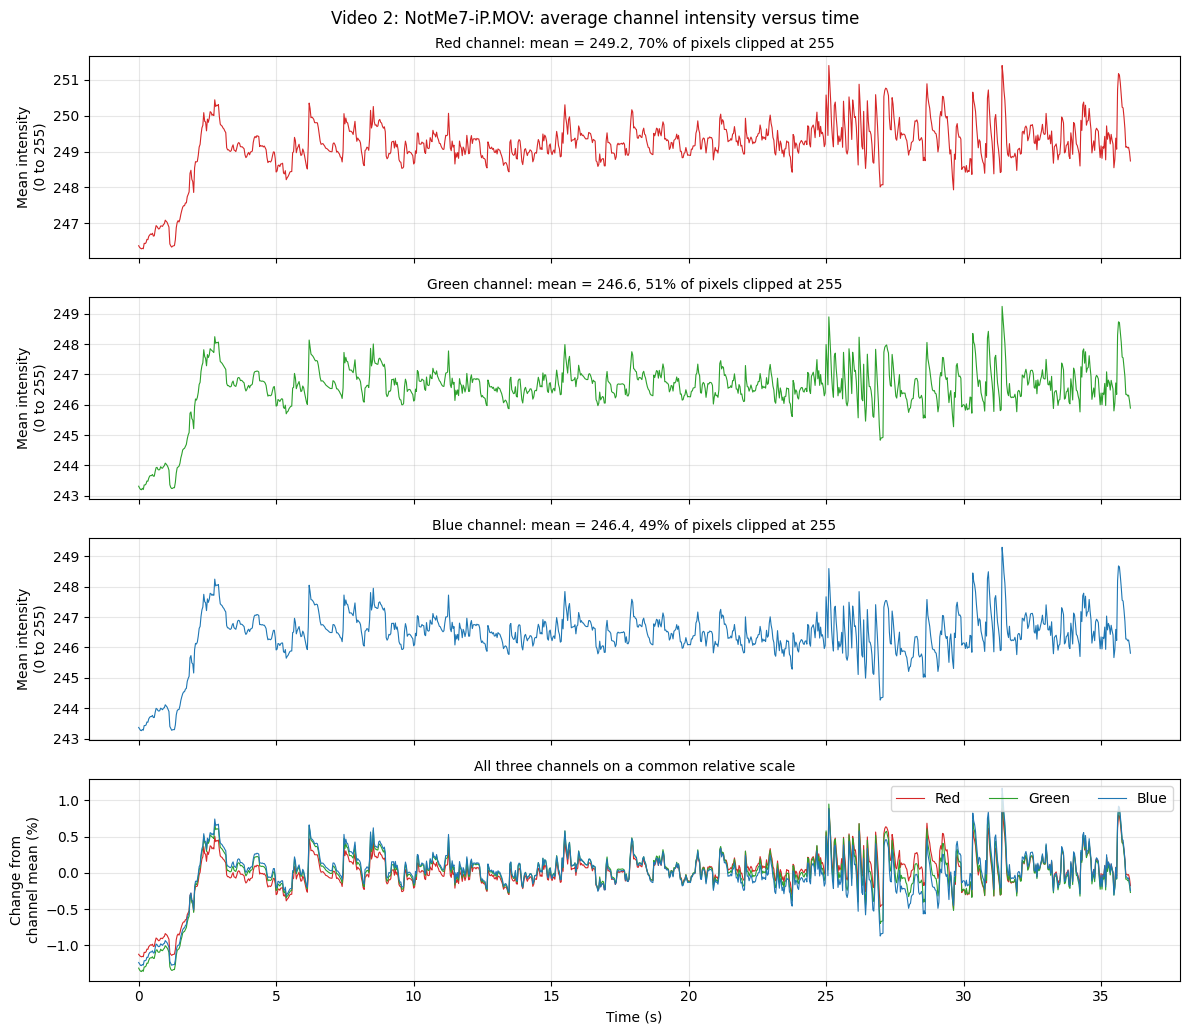

In [18]:
plot_rgb(v2)

**Observations.**

- **All three channels are near the top of the range** (about 247 to 249 out of 255), and 49% to 70% of the pixels are clipped. This matches the nearly white frame.
- **The first 3 seconds** show a large rise of about 3 intensity units. This looks like the camera's auto-exposure settling.
- **After that, the three channels move together** almost exactly, with no obvious regular beat. Blood absorbs red, green, and blue very differently, so changes caused by blood would differ between the channels. Identical changes in all three point to the camera or the light source instead.

## Part 2: Design a filter to isolate the pulsatile frequency of interest

Same design as Video 1 (see Video 1, Part 2, for the decisions and rationale). This video is also 30 fps, so the filter is identical: $N = 239$, $M = 119$, cutoffs of 0.55 Hz and 3.65 Hz, and at least 40 dB of stopband attenuation.

In [19]:
filt2 = design_bandpass(v2)

Kaiser-window FIR bandpass for fs = 30 Hz
  length N = 239 taps (7.97 s), half-length M = 119 samples (3.97 s), beta = 3.631
  cutoffs (-6 dB): 0.55 Hz (33 bpm) and 3.65 Hz (219 bpm)
  -3 dB band: 0.594 to 3.607 Hz (36 to 216 bpm)
  passband 0.7-3.5 Hz: gain -0.042 to +0.099 dB
  stopbands below 0.4 Hz and above 3.8 Hz: at least 40.0 dB attenuation (spec 40 dB)


## Part 3: Plot the impulse response of your filter

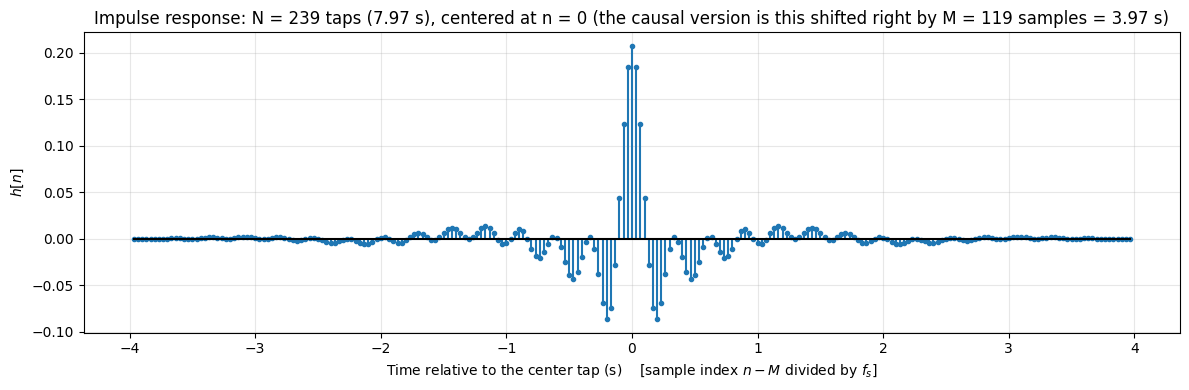

In [20]:
plot_impulse(filt2)

## Part 4: How long do you estimate it would take for the edge effects to become negligible for your filter?

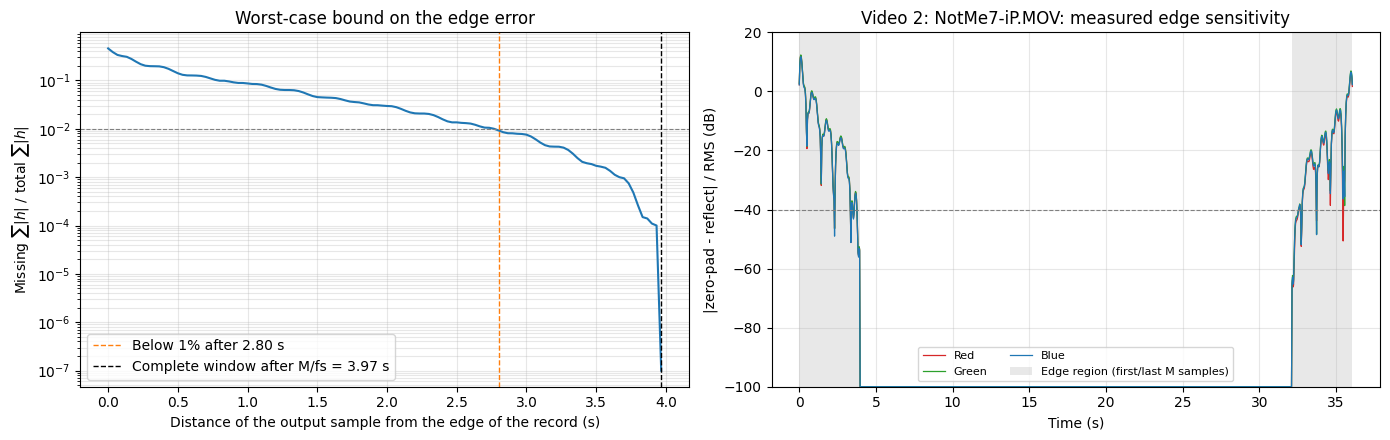

Complete filter window (strict):       119 samples = 3.97 s from each end
Worst-case bound below 1% of max |y|:  84 samples = 2.80 s from each end
Red  : measured difference stays below 1% of RMS from 3.77 s to 32.57 s  (i.e. 3.77 s and 3.50 s in from the ends)
Green: measured difference stays below 1% of RMS from 3.77 s to 32.53 s  (i.e. 3.77 s and 3.53 s in from the ends)
Blue : measured difference stays below 1% of RMS from 3.77 s to 32.53 s  (i.e. 3.77 s and 3.53 s in from the ends)


In [21]:
edge_analysis(v2, filt2)

**Answer: the same as Video 1: small after about 3 s and gone after $M/f_s = 3.97$ s from each end.** The filter is the same, so the strict answer and the 2.80 s worst-case bound are unchanged.

This video shows why I use the strict value. The auto-exposure transient at the start is large compared with what remains after filtering. At the very start, the zero-padding and reflection outputs differ by more than the steady-state RMS (above 0 dB), and the difference stays above 1% of the RMS until about 3.8 s after the start and 3.5 s before the end, almost the full $M/f_s = 3.97$ s and longer than for Video 1 (2.9 s and 3.3 s).

## Part 5: Plot the magnitude response of your filter

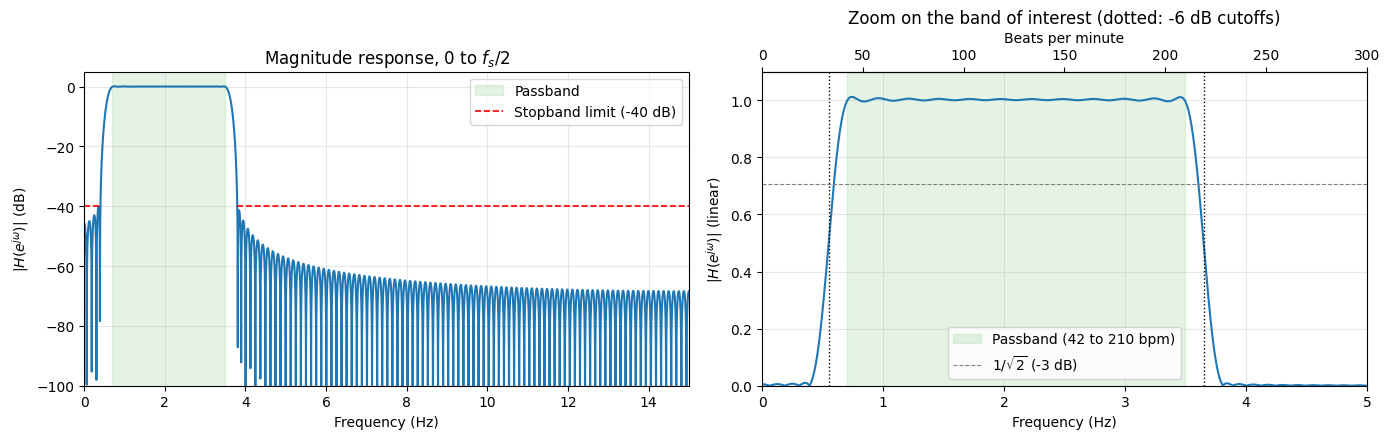

In [22]:
plot_magnitude(filt2)

Identical to Video 1, Part 5.

## Part 6: Plot the phase response of your filter

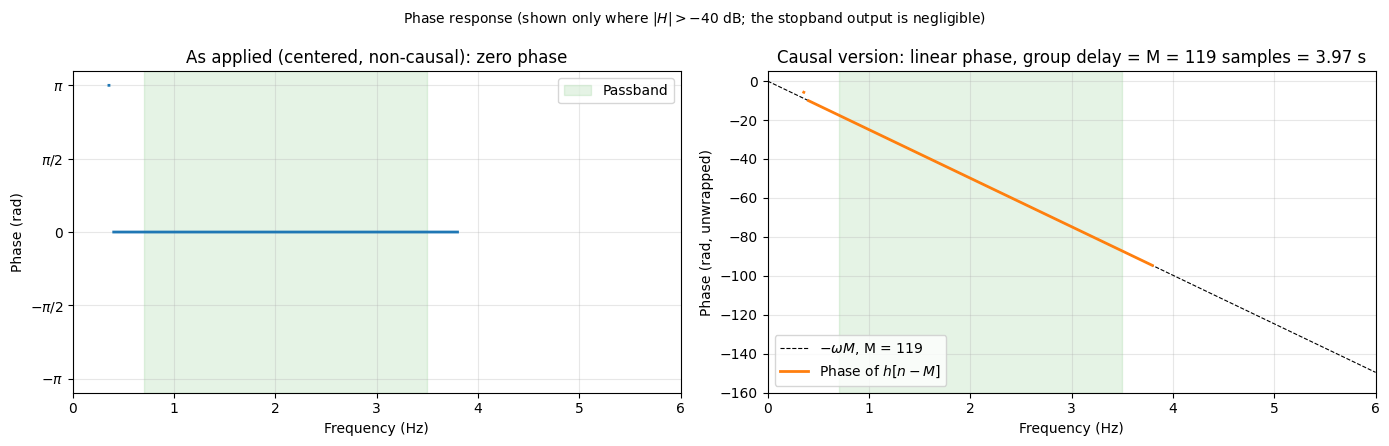

In [23]:
plot_phase(filt2)

Identical to Video 1, Part 6: zero phase as applied, and linear phase with a 3.97 s group delay for the causal version.

## Part 7: Plot the output of your filter for each of the color channels

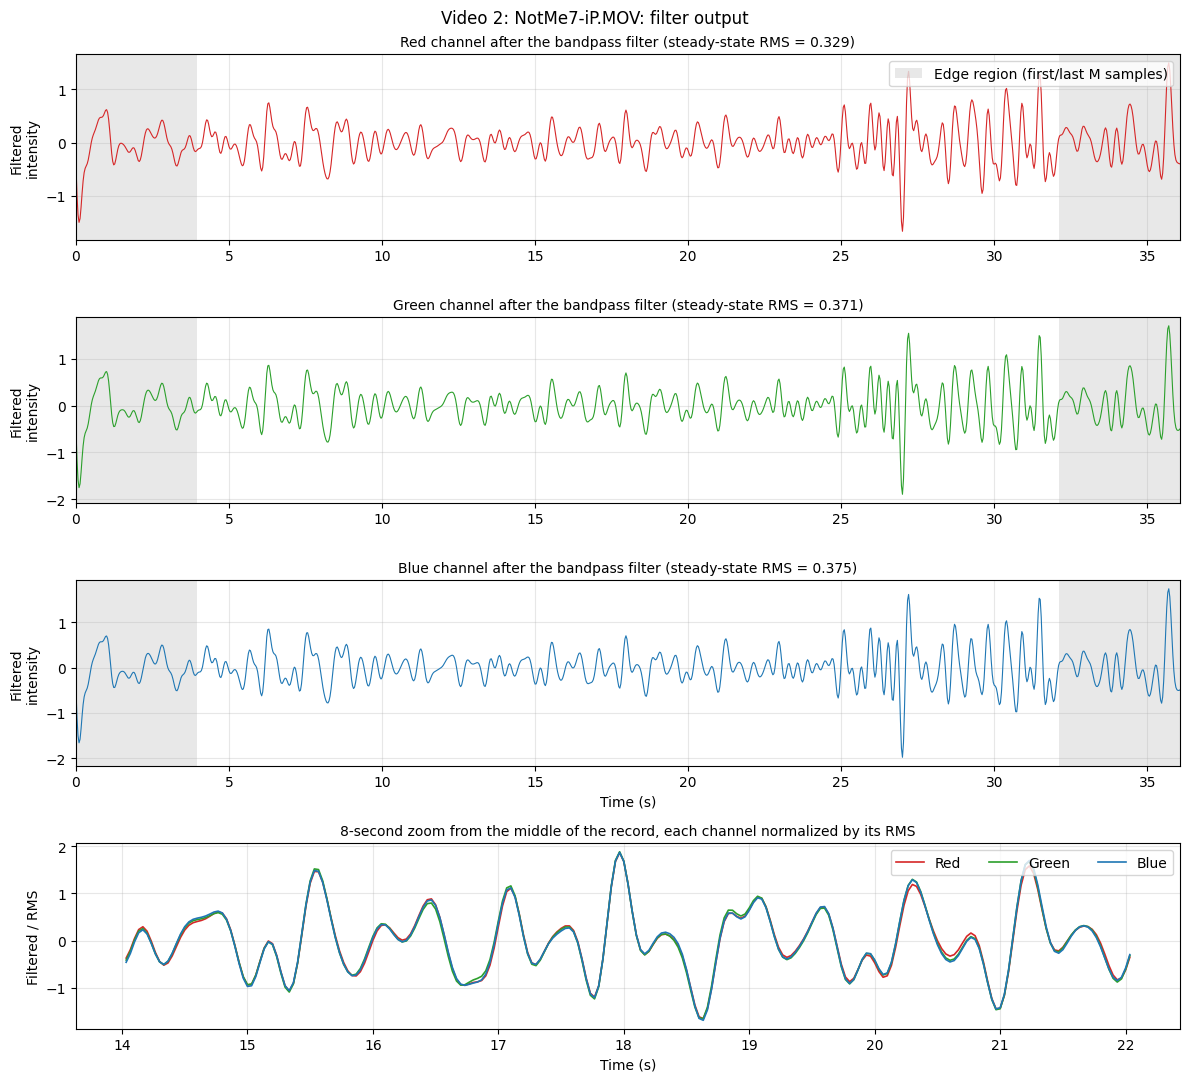

In [24]:
y2 = filter_video(v2, filt2) if v2 is not None else None
plot_filtered(y2, v2['label'] if v2 is not None else '')

- The filtered signals look like bandlimited noise. The amplitude and spacing of the oscillations change from cycle to cycle, with no regular beat like Video 1's, and the fluctuations grow after about 25 s.
- The three channels are nearly identical in the 8-second zoom. This is the common-mode behavior noted in Part 1.
- The large spikes at the start are the filter's response to the auto-exposure transient, inside the edge region.

## Part 8: Determine an approach to estimating the power spectral density

Same approach as Video 1 (see Video 1, Part 8): a Welch PSD of the steady-state filtered output, Hann window, 10 s segments, 50% overlap, an 8192-point FFT, and one-sided density scaling.

## Part 9: Plot the Power Spectral Density for each of the color channels

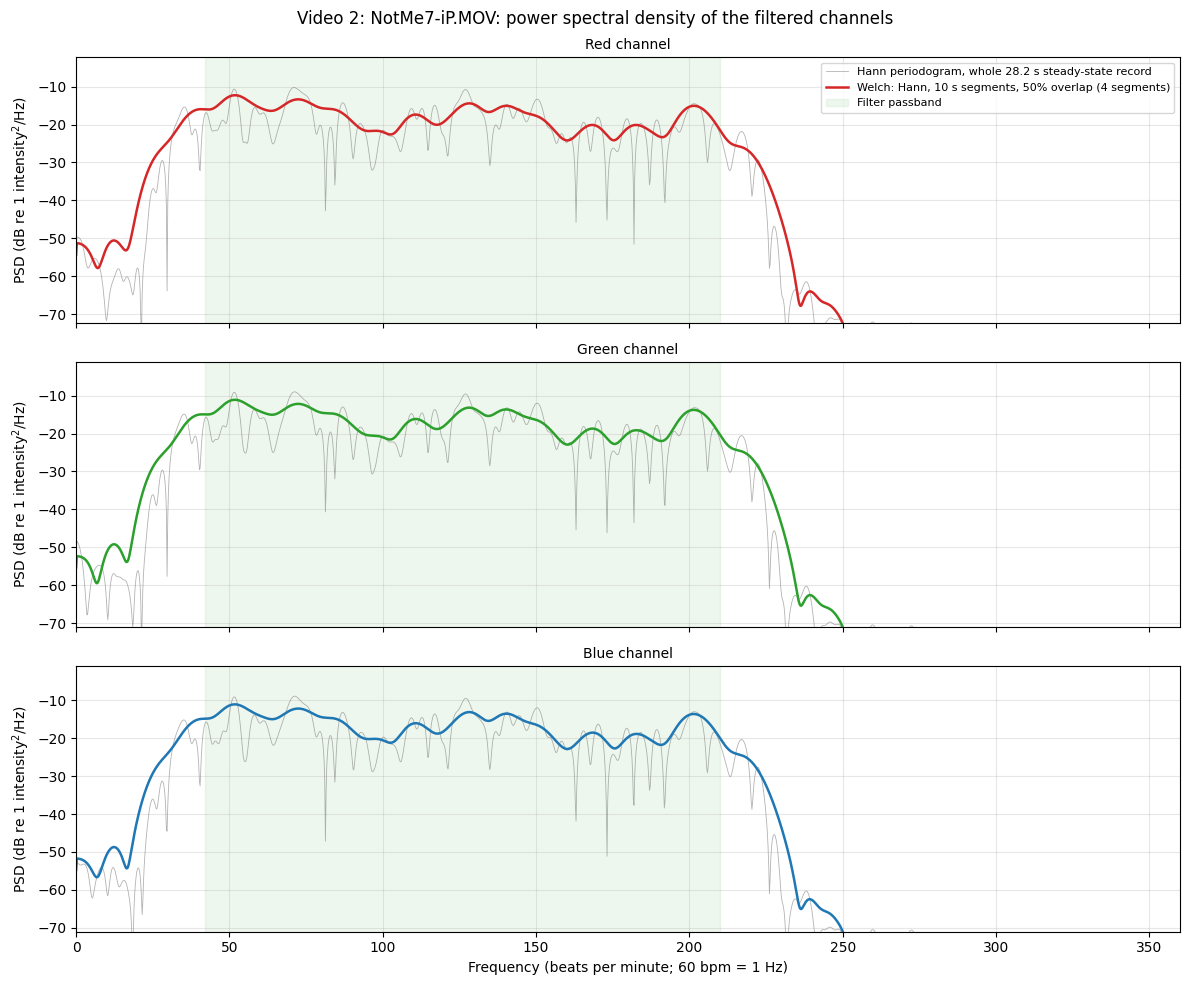

In [25]:
psd2 = compute_psd(y2)
plot_psd(psd2, v2['label'] if v2 is not None else '')

- There is no dominant peak. The PSD has several bumps of similar height across the passband, and the gray single periodogram has its largest peak at a different frequency than the Welch estimate. This is what a noise spectrum looks like.
- There is no harmonic structure, unlike Video 1's evenly spaced peaks at 1×, 2×, and 3× the heart rate.
- The three channels have nearly the same PSD shape, again consistent with a common-mode source.

## Part 10: Estimate the pulse (heart) rate, if present

Same method and presence test as Video 1 (see Video 1, Part 10).

Channel   Mean  Clipped  Pulse RMS   AC/DC  Welch HR  Peak frac  10-s median  10-s IQR  Pulse?
Red      249.2    69.6%      0.329  0.132%  51.9 bpm       0.25     70.8 bpm  25.0 bpm  no
Green    246.6    51.3%      0.371  0.150%  51.9 bpm       0.25     70.8 bpm  25.9 bpm  no
Blue     246.4    48.9%      0.375  0.152%  51.6 bpm       0.25     70.8 bpm  25.7 bpm  no

Pulse NOT present: only 0 of 3 channels pass both tests (peak fraction >= 0.5, 10-s IQR <= 10 bpm).


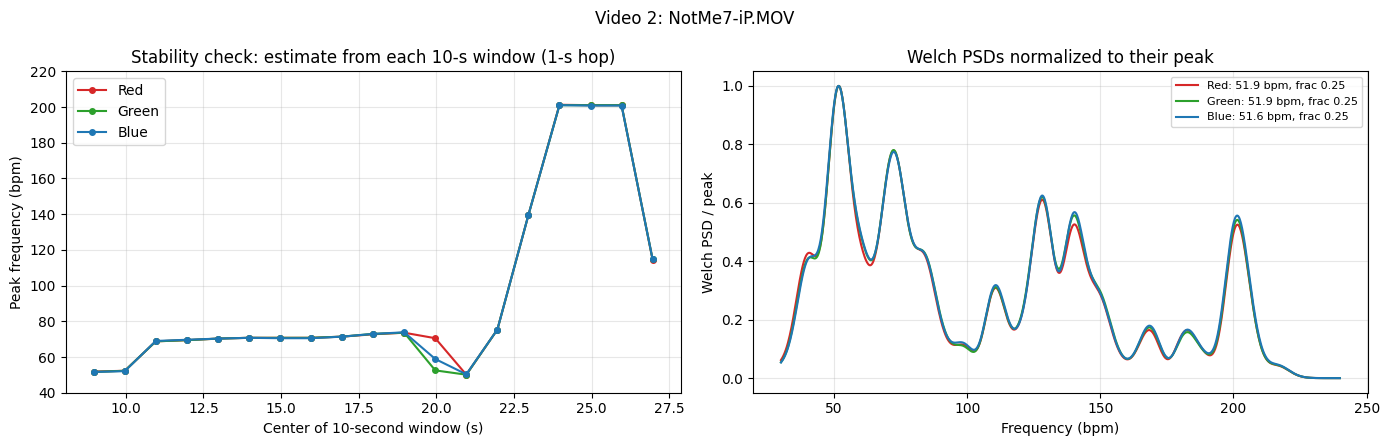

In [26]:
hr2 = estimate_pulse(y2, psd2, v2)

**A pulse does not appear to be present.**

- **Peak fraction 0.25.** The largest in-band peak holds only a quarter of the passband power, well below the 0.5 threshold and not far above what a flat noise spectrum gives (0.14). The Welch PSD has several peaks of similar height (at about 52, 72, 128, 140, and 200 bpm) and no harmonic pattern.
- **Unstable estimate.** The 10-second estimates sit near 70 bpm from about 11 to 19 s, then jump to 50 bpm, then to 200 bpm. The interquartile range is about 25 bpm, compared with about 3 bpm for Video 1.
- **Disagreement between methods.** The Welch peak (about 52 bpm) and the largest peak of the single periodogram (about 71 bpm) differ. A strong periodic component would give the same peak with both methods.
- **Common-mode behavior.** All three channels fluctuate identically, which is not how blood absorption behaves.

The stretch near 70 bpm means I cannot rule out a weak periodic component in part of the recording. But it does not hold across the record, it has no harmonics, and the frame does not look like light through tissue. Any single number read off this PSD would be the largest noise peak, not a heart rate.

## Part 11: Which color channels were most helpful for estimating the pulse rate?

**None of them.** No channel passed the presence test, and all three behaved the same way.

The three channels are so alike here because the fluctuations are not coming from blood: they look like the camera's exposure or the flash brightness changing, which affects every color equally. This contrast is the useful lesson from this video. In Video 1, the channels differed in amplitude in the way blood absorption predicts (green and blue strong, red weak only because of clipping). Here they do not.

# Video 3: My finger

### Recording procedure

To match the provided videos (iPhone, flash on, 1080p at 30 fps):

1. **Camera settings.** Settings → Camera → Record Video → **1080p at 30 fps**. If the notebook cannot decode the file, also set Settings → Camera → Formats → **Most Compatible** (H.264 instead of HEVC).
2. **Turn the light on.** Open the Camera app in **Video** mode and set the flash (lightning bolt) to **On**. In video mode the flash stays lit as a torch.
3. **Position.** Sit, rest my forearm and hand on a table at about heart level, and hold the phone steady with the other hand.
4. **Cover the lens and the flash.** Rest the pad of my index fingertip lightly over the rear camera lens(es) **and** the flash. Pressing hard squeezes blood out of the fingertip and weakens the pulse. Touching too lightly lets room light in and makes the signal sensitive to movement.
5. **Record about 45 seconds** without moving. Start recording with a volume button so the finger does not have to move. If I start recording first and then place the finger, I set `MY_TRIM_START` above to drop those first seconds.
6. **Reference (optional, but a good check).** During the recording, read my heart rate from a smartwatch, or count my pulse at the wrist for 30 s and double it. Enter it as `MY_REFERENCE_BPM`.
7. **Transfer the file** (AirDrop, iCloud, or a USB cable) into this folder and name it `MyFinger7-iP.MOV`, or change `MY_VIDEO_FILE` above to match. Then re-run the notebook.

If the recording is at 60 fps instead of 30, nothing else needs to change. The filter is specified in hertz and is redesigned for the actual frame rate, and the edge region stays about 4 s.

## Part 1: Plot the average intensity of the red, blue, and green channels versus time

C:\Users\jknap\AppData\Local\Temp\ipykernel_234160\1332239765.py:11: RuntimeWarning: invalid value encountered in divide
  rel = 100 * (rgb / rgb.mean(axis=0) - 1)


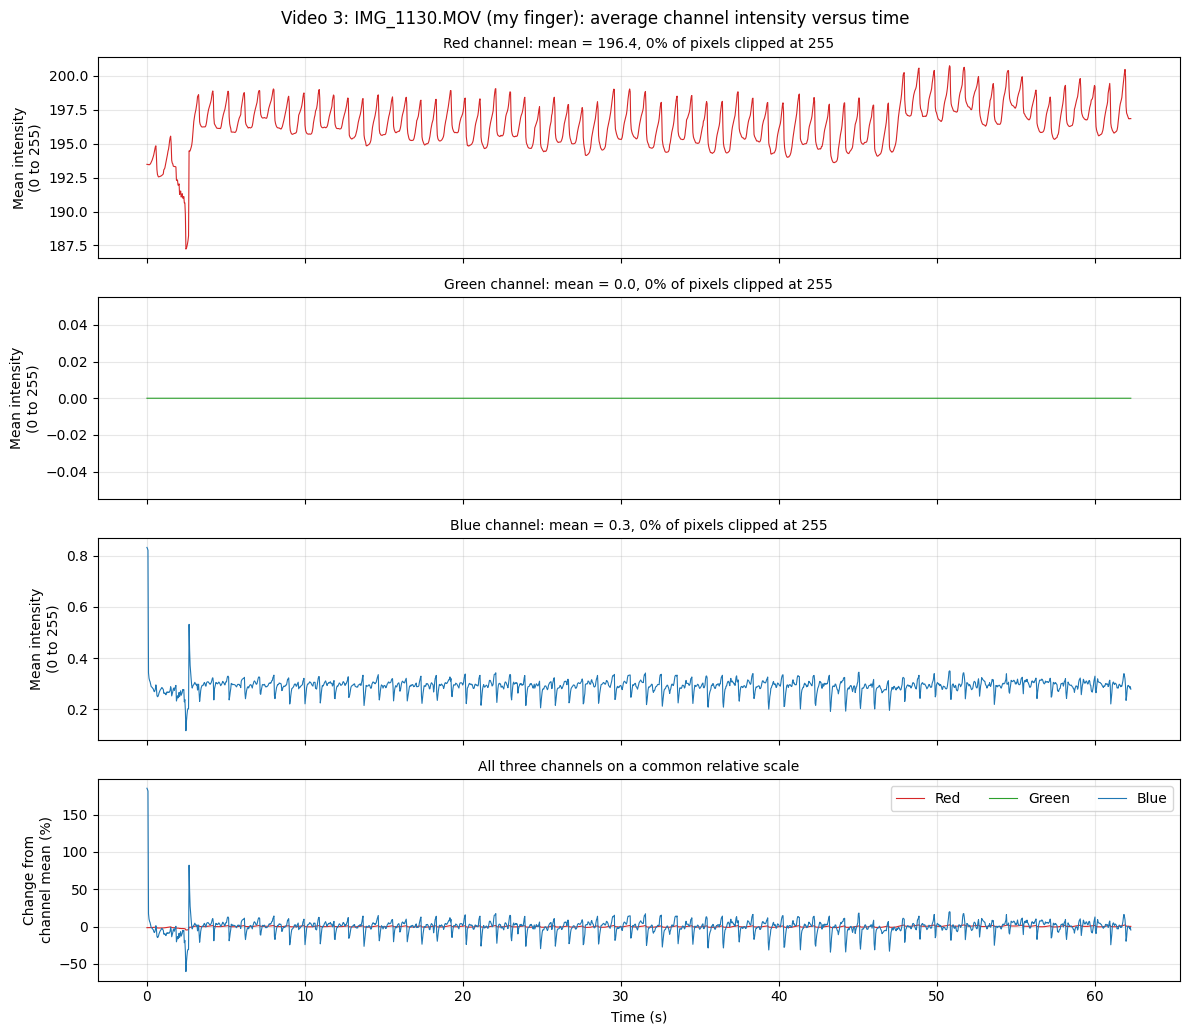

In [27]:
plot_rgb(v3)

*(Fill in after running: describe what this plot shows for my recording.)*

## Part 2: Design a filter to isolate the pulsatile frequency of interest

Same design decisions as Video 1 (see Video 1, Part 2). The specifications are in hertz, so at 30 fps this is the same filter. At any other frame rate it has the same specifications with a proportionally longer or shorter length.

In [28]:
filt3 = design_bandpass(v3)

Kaiser-window FIR bandpass for fs = 30 Hz
  length N = 239 taps (7.97 s), half-length M = 119 samples (3.97 s), beta = 3.631
  cutoffs (-6 dB): 0.55 Hz (33 bpm) and 3.65 Hz (219 bpm)
  -3 dB band: 0.594 to 3.607 Hz (36 to 216 bpm)
  passband 0.7-3.5 Hz: gain -0.042 to +0.099 dB
  stopbands below 0.4 Hz and above 3.8 Hz: at least 40.0 dB attenuation (spec 40 dB)


## Part 3: Plot the impulse response of your filter

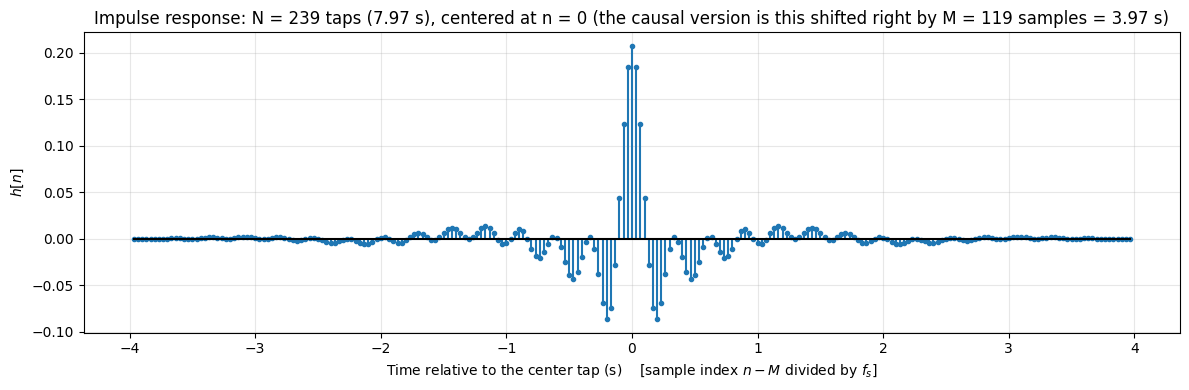

In [29]:
plot_impulse(filt3)

## Part 4: How long do you estimate it would take for the edge effects to become negligible for your filter?

C:\Users\jknap\AppData\Local\Temp\ipykernel_234160\1940065039.py:45: RuntimeWarning: invalid value encountered in divide
  rel_db = 20 * np.log10(np.maximum(diff / rms, 1e-5))


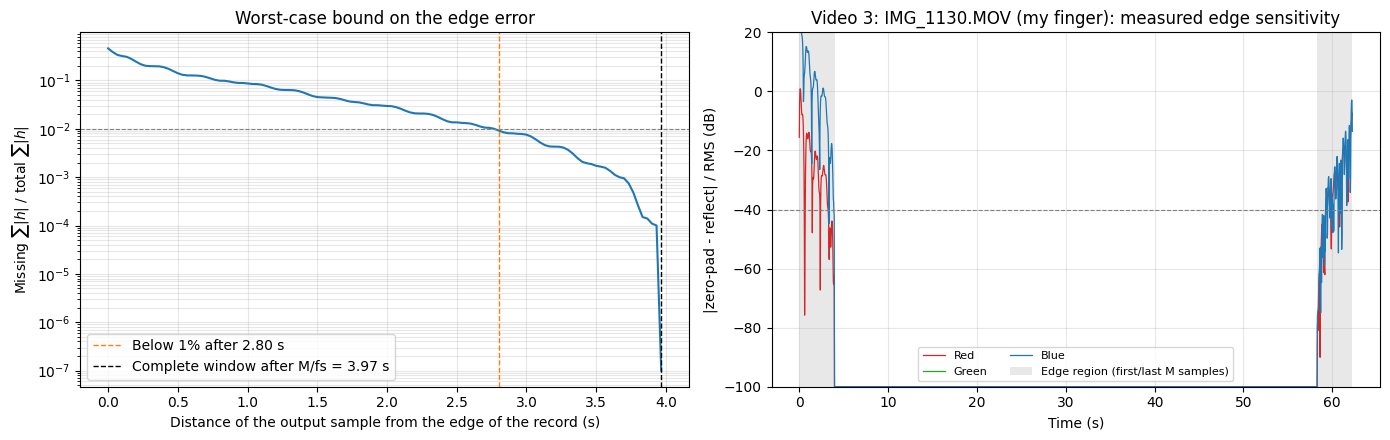

Complete filter window (strict):       119 samples = 3.97 s from each end
Worst-case bound below 1% of max |y|:  84 samples = 2.80 s from each end
Red  : measured difference stays below 1% of RMS from 3.27 s to 59.23 s  (i.e. 3.27 s and 3.03 s in from the ends)
Green: measured difference stays below 1% of RMS from 0.00 s to 62.27 s  (i.e. 0.00 s and 0.00 s in from the ends)
Blue : measured difference stays below 1% of RMS from 3.90 s to 59.23 s  (i.e. 3.90 s and 3.03 s in from the ends)


In [30]:
edge_analysis(v3, filt3)

*(Fill in after running. At 30 fps the strict answer is the same as Videos 1 and 2: $M/f_s = 3.97$ s from each end. Comment on what the measured plot shows for my recording.)*

## Part 5: Plot the magnitude response of your filter

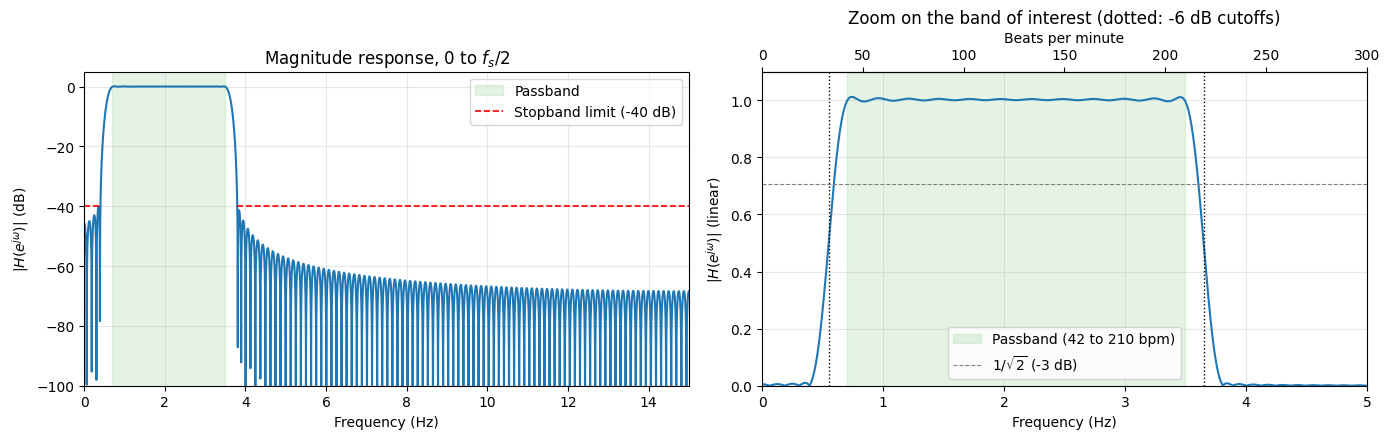

In [31]:
plot_magnitude(filt3)

*(Fill in after running: describe what this plot shows for my recording.)*

## Part 6: Plot the phase response of your filter

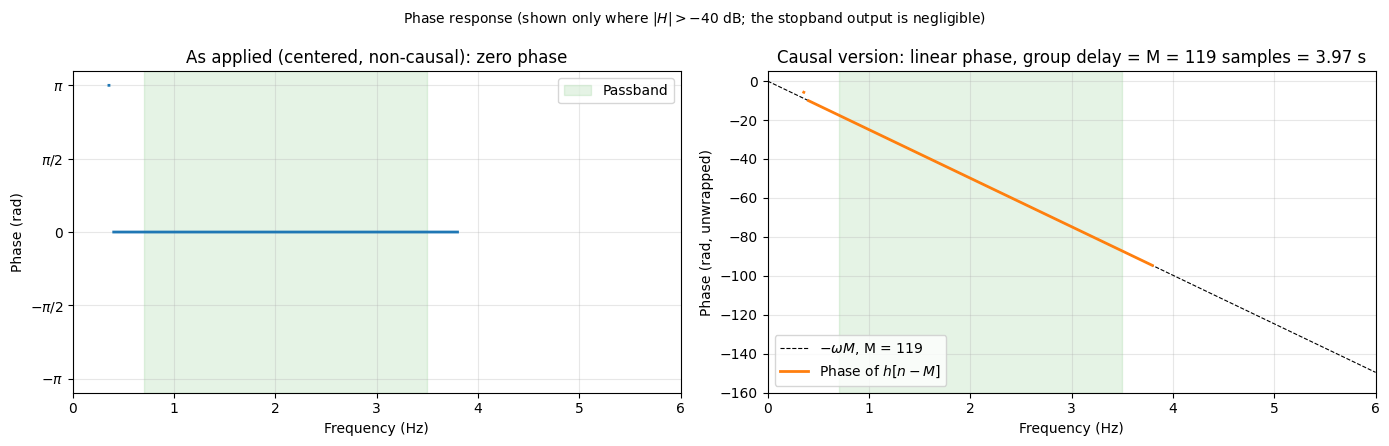

In [32]:
plot_phase(filt3)

*(Fill in after running: describe what this plot shows for my recording.)*

## Part 7: Plot the output of your filter for each of the color channels

C:\Users\jknap\AppData\Local\Temp\ipykernel_234160\1940065039.py:104: RuntimeWarning: invalid value encountered in divide
  ax.plot(t[sel], y[sel, c] / y[yd["steady"], c].std(), color=CH_COLORS[c], lw=1.2, label=CH_NAMES[c])


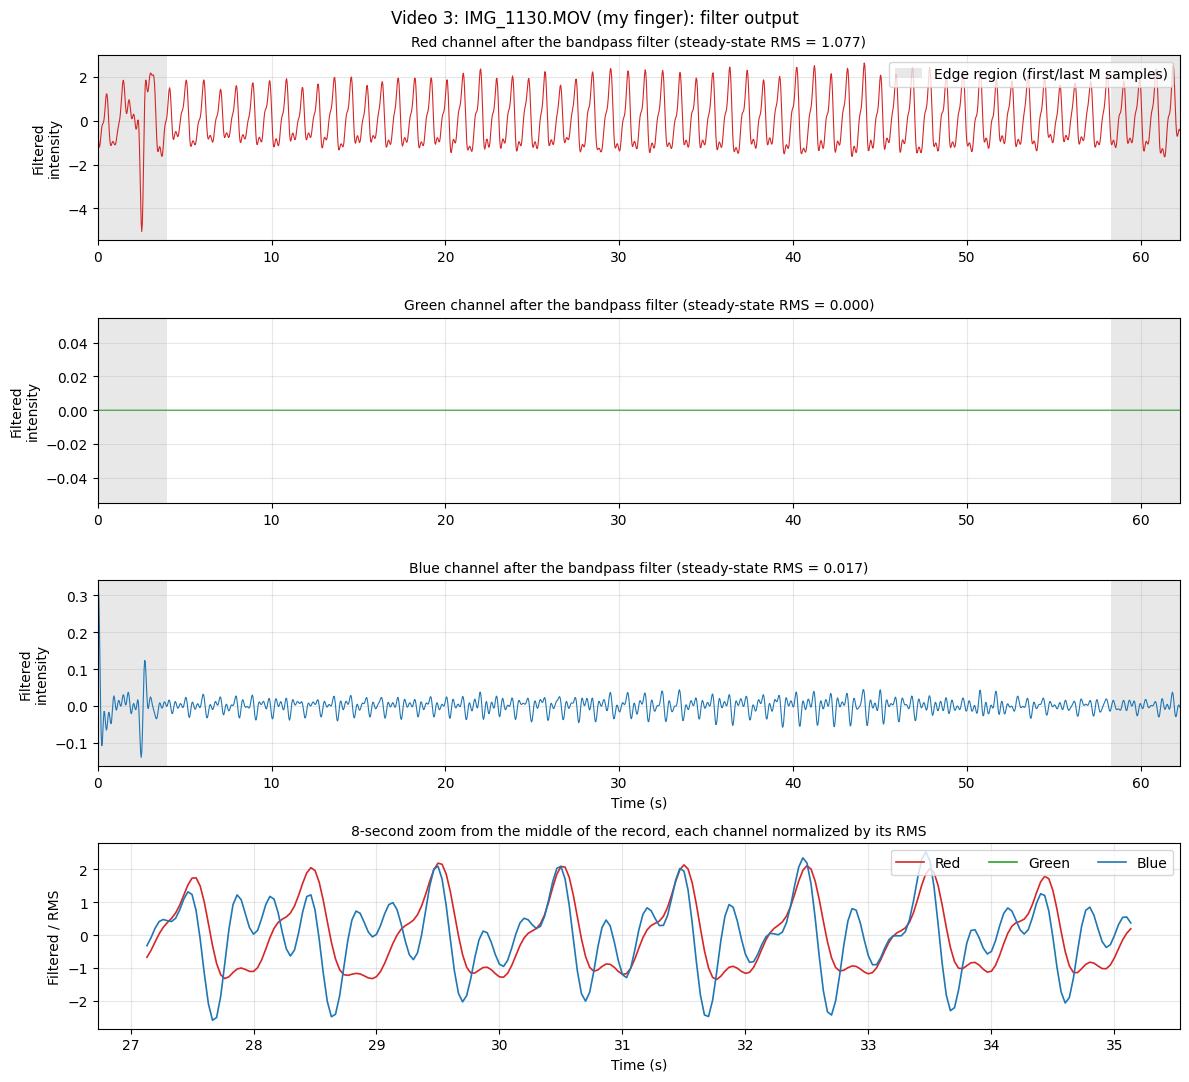

In [33]:
y3 = filter_video(v3, filt3) if v3 is not None else None
plot_filtered(y3, v3['label'] if v3 is not None else '')

*(Fill in after running: describe what this plot shows for my recording.)*

## Part 8: Determine an approach to estimating the power spectral density

Same approach as Video 1 (see Video 1, Part 8).

## Part 9: Plot the Power Spectral Density for each of the color channels

C:\Users\jknap\AppData\Local\Temp\ipykernel_234160\1363876891.py:28: RuntimeWarning: divide by zero encountered in log10
  peak = 10 * np.log10(Pw[:, c].max())


ValueError: Axis limits cannot be NaN or Inf

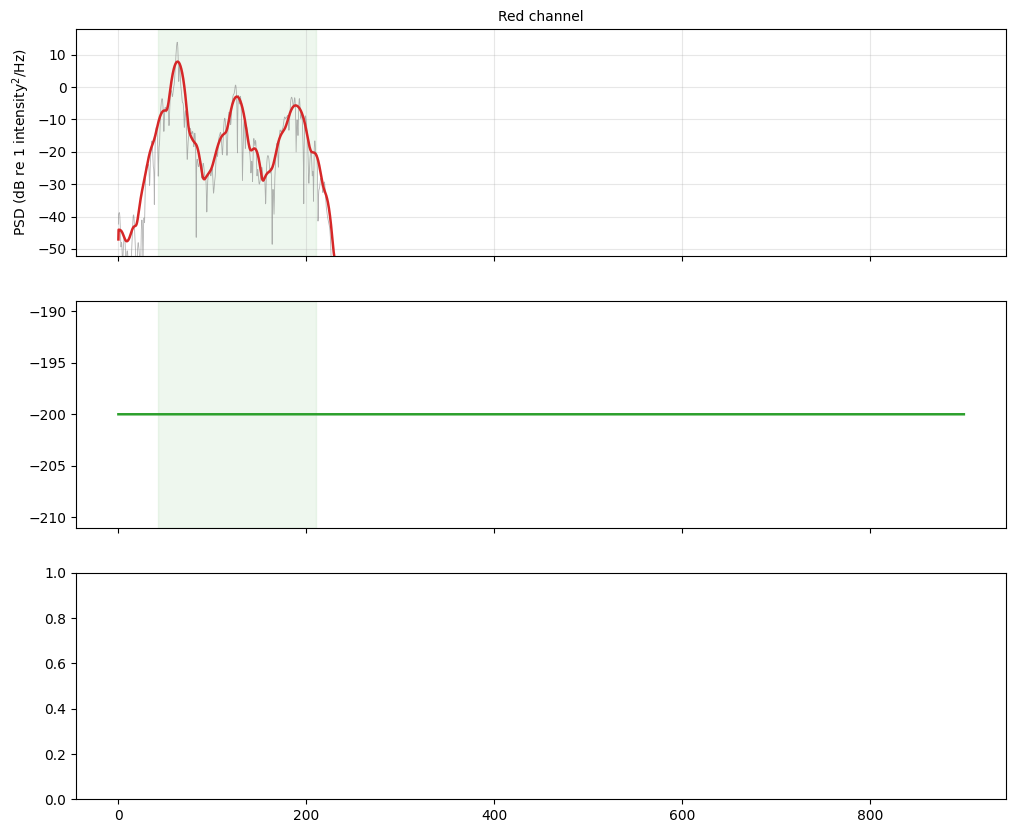

In [34]:
psd3 = compute_psd(y3)
plot_psd(psd3, v3['label'] if v3 is not None else '')

*(Fill in after running: describe what this plot shows for my recording.)*

## Part 10: Estimate the pulse (heart) rate, if present

Same method and presence test as Video 1 (see Video 1, Part 10).

In [ ]:
hr3 = estimate_pulse(y3, psd3, v3, reference_bpm=MY_REFERENCE_BPM)

*(Fill in after running: state whether a pulse is present, the estimated rate from the printed summary, and how it compares with `MY_REFERENCE_BPM`.)*

## Part 11: Which color channels were most helpful for estimating the pulse rate?

*(Fill in after running: rank the channels using the table above (pulse RMS, peak fraction, and 10-s IQR), and note whether the red channel was clipped as in Video 1.)*

## Part 12: What, if anything, did you learn from this homework?

* **Photoplethysmography with a phone**
  A phone camera and its flash are enough to measure the pulse. Each heartbeat increases the blood volume in the fingertip, which absorbs more light, so the average pixel intensity dips once per beat. The pulsatile part is small: about 1% of the green channel's mean.

* **Clipping can hide the strongest signal**
  Physically, red light carries the most information through a finger, but the camera clipped about 91% of the red pixels at 255, so the red average barely moved. A channel can have the most signal at the sensor and still be the least useful after clipping and quantization.

* **The transition width sets the filter length and the edge effects**
  The narrowest transition, between fast breathing (0.4 Hz) and a slow heart rate (0.7 Hz), sets the Kaiser filter length to about 8 s. A centered FIR filter's edge effects last exactly $M$ samples, so that one design decision costs about 4 s at each end of a 36 s record.

* **Welch's method is a resolution versus variance tradeoff**
  Longer segments give finer frequency resolution but fewer averages. Because the heart rate varies by a few bpm from breath to breath anyway, 10 s segments were a good balance. Zero padding makes the peak easier to locate, but it does not add resolution.

* **A negative control and a presence test**
  Every PSD has a largest peak, even a noise spectrum. Video 2 showed that I need a test (here, peak fraction and stability over time) before reporting a heart rate. It also showed that when all three color channels move identically, the cause is probably the camera or the lighting rather than blood, because blood absorbs each color differently.

## Part 13: What new questions, if any, do you have?

* Would averaging only the unclipped pixels, or locking the camera exposure lower, make the red channel the most useful one?
* How well does this work without the flash, for example from a face video in room light (remote PPG), where the pulsatile signal is much smaller?
* How would I track the heart rate beat by beat (heart rate variability) instead of a single average over 30 seconds?